# Diagnóstico del dataset Colombia Housing Properties Price

Análisis exploratorio del dataset inmobiliario de Colombia (`co_properties.csv`): estructura del esquema, calidad de datos (nulos, duplicados, inconsistencias), estadísticas descriptivas, valores atípicos y variables candidatas para predecir el precio de la vivienda. En esta fase **no se modifican los datos**, solo se diagnostica.

In [0]:
# Descarga del dataset desde Kaggle y extracción en un volumen de Unity Catalog
import os, zipfile
import requests

# Esquema y volumen dedicados al proyecto de vivienda
spark.sql("CREATE SCHEMA IF NOT EXISTS workspace.vivienda")
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.vivienda.raw_data")

VOL = "/Volumes/workspace/vivienda/raw_data"
url = "https://www.kaggle.com/api/v1/datasets/download/julianusugaortiz/colombia-housing-properties-price"
zip_path = f"{VOL}/colombia_housing_properties.zip"

if not os.path.exists(zip_path):
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(1024 * 1024):
                f.write(chunk)
print(f"ZIP descargado: {os.path.getsize(zip_path)/1e6:.1f} MB")

with zipfile.ZipFile(zip_path) as z:
    print("Archivos en el ZIP:", z.namelist())
    z.extractall(VOL)
    for info in z.infolist():
        print(f"  - {info.filename}: {info.file_size/1e6:.1f} MB sin comprimir")

ZIP descargado: 153.0 MB
Archivos en el ZIP: ['co_properties.csv']
  - co_properties.csv: 617.7 MB sin comprimir


In [0]:
# Registro del CSV crudo (sin modificaciones) como tabla Delta en Unity Catalog
import os
VOL = "/Volumes/workspace/vivienda/raw_data"
csv_files = [f for f in os.listdir(VOL) if f.endswith(".csv")]
print("CSV extraídos:", csv_files)

df_raw = (spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("multiLine", True)  # el CSV original tiene saltos de línea dentro de campos entrecomillados
    .csv(f"{VOL}/{csv_files[0]}"))

df_raw.write.mode("overwrite").option("overwriteSchema", True) \
    .saveAsTable("workspace.vivienda.co_properties")

print(f"Registros: {df_raw.count():,}")
print(f"Columnas: {len(df_raw.columns)}")

CSV extraídos: ['co_properties.csv']
Registros: 1,005,959
Columnas: 25


In [0]:
# 1) Estructura: dimensiones, columnas y tipos de datos
df = spark.table("workspace.vivienda.co_properties")
print(f"Registros: {df.count():,} | Columnas: {len(df.columns)}")
print("\nEsquema:")
df.printSchema()

print("\nResumen de columnas por tipo de dato:")
tipos = {}
for f in df.schema.fields:
    tipos.setdefault(f.dataType.simpleString(), []).append(f.name)
for t, cols in sorted(tipos.items()):
    print(f"  {t} ({len(cols)}): {cols}")

Registros: 1,005,959 | Columnas: 25

Esquema:
root
 |-- id: string (nullable = true)
 |-- ad_type: string (nullable = true)
 |-- start_date: string (nullable = true)
 |-- end_date: string (nullable = true)
 |-- created_on: string (nullable = true)
 |-- lat: string (nullable = true)
 |-- lon: string (nullable = true)
 |-- l1: string (nullable = true)
 |-- l2: string (nullable = true)
 |-- l3: string (nullable = true)
 |-- l4: string (nullable = true)
 |-- l5: string (nullable = true)
 |-- l6: string (nullable = true)
 |-- rooms: string (nullable = true)
 |-- bedrooms: string (nullable = true)
 |-- bathrooms: string (nullable = true)
 |-- surface_total: string (nullable = true)
 |-- surface_covered: string (nullable = true)
 |-- price: string (nullable = true)
 |-- currency: string (nullable = true)
 |-- price_period: string (nullable = true)
 |-- title: string (nullable = true)
 |-- description: string (nullable = true)
 |-- property_type: string (nullable = true)
 |-- operation_type: s

In [0]:
# 5) Calidad de datos: nulos y duplicados
from pyspark.sql import functions as F

total = df.count()
print(f"Total de registros: {total:,}")

row = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
print("\nValores nulos por columna:")
for c, n in sorted(row.items(), key=lambda kv: -kv[1]):
    print(f"  {c}: {n:,} ({n/total:.1%})")

sin_duplicados = df.dropDuplicates().count()
print(f"\nDuplicados exactos (todas las columnas): {total - sin_duplicados:,}")

if "id" in df.columns:
    ids_distintos = df.select("id").distinct().count()
    print(f"IDs distintos: {ids_distintos:,} (registros con id repetido: {total - ids_distintos:,})")

Total de registros: 1,005,959

Valores nulos por columna:
  surface_total: 964,688 (95.9%)
  l6: 950,653 (94.5%)
  surface_covered: 946,034 (94.0%)
  price_period: 884,812 (88.0%)
  l5: 846,463 (84.1%)
  rooms: 833,748 (82.9%)
  l4: 731,718 (72.7%)
  bedrooms: 629,953 (62.6%)
  lon: 265,880 (26.4%)
  lat: 265,700 (26.4%)
  bathrooms: 206,330 (20.5%)
  l3: 68,558 (6.8%)
  operation_type: 7,255 (0.7%)
  description: 7,144 (0.7%)
  property_type: 7,104 (0.7%)
  currency: 7,045 (0.7%)
  price: 6,993 (0.7%)
  title: 6,515 (0.6%)
  l1: 6,186 (0.6%)
  l2: 6,036 (0.6%)
  created_on: 5,340 (0.5%)
  end_date: 5,102 (0.5%)
  start_date: 4,538 (0.5%)
  ad_type: 4,019 (0.4%)
  id: 2 (0.0%)

Duplicados exactos (todas las columnas): 3,017
IDs distintos: 1,002,860 (registros con id repetido: 3,099)


In [0]:
# 6) Estadísticas descriptivas de las variables numéricas
# El CSV entrega todas las columnas como texto: se convierten a double las numéricas.
# try_cast devuelve NULL para las pocas filas desalineadas (valores de texto en columnas numéricas).
num_cols = ["price", "rooms", "bedrooms", "bathrooms", "surface_total", "surface_covered", "lat", "lon"]
cat_cols = [c for c in df.columns if c not in num_cols]
df_num = df.select([F.expr(f"try_cast(`{c}` AS DOUBLE)").alias(c) for c in num_cols])
print(f"Variables numéricas ({len(num_cols)}): {num_cols}")
print(f"Variables de texto ({len(cat_cols)}): {cat_cols}")

stats_pd = (df_num
    .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
    .toPandas()
    .set_index("summary")
    .T)
display(stats_pd)

Variables numéricas (8): ['price', 'rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered', 'lat', 'lon']
Variables de texto (17): ['id', 'ad_type', 'start_date', 'end_date', 'created_on', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'currency', 'price_period', 'title', 'description', 'property_type', 'operation_type']


count,mean,stddev,min,25%,50%,75%,max
998945,4.067482930708027E8,2.420278753898034E9,0.0,1800000.0,1.5E8,3.95E8,1.6E12
171697,3.1238751987512887,1.8000829263107203,1.0,2.0,3.0,3.0,40.0
375612,2.8067793361234465,1.951669036661688,0.0,2.0,3.0,3.0,96.0
799433,2.414536302604471,1.4125998041891394,1.0,2.0,2.0,3.0,20.0
41235,982.5766703043531,7014.494314095247,10.0,64.0,100.0,223.0,200000.0
59898,1502.9699656082007,152110.43337989596,1.0,62.0,96.0,188.0,3.15201E7
739891,5.822520230752501,2.328036488639494,-75.64033,4.642,5.04689287,6.3364975979,550.0
739807,59553.31043709407,1.355219522542167E7,-180.0,-75.6033843,-75.081,-74.0558524,8.0E9


In [0]:
# 7) Valores atípicos en variables numéricas (criterio IQR: fuera de Q1-1.5·IQR / Q3+1.5·IQR)
outlier_rows = []
for c in num_cols:
    q = df_num.approxQuantile(c, [0.25, 0.75], 0.01)
    if q is None or len(q) < 2 or q[0] is None or q[1] is None:
        continue
    iqr = q[1] - q[0]
    lo, hi = q[0] - 1.5 * iqr, q[1] + 1.5 * iqr
    n_out = df_num.filter((F.col(c) < lo) | (F.col(c) > hi)).count()
    outlier_rows.append((c, q[0], q[1], lo, hi, n_out, round(n_out / total, 4)))

display(spark.createDataFrame(
    outlier_rows,
    "variable string, q1 double, q3 double, limite_inferior double, limite_superior double, atipicos long, pct_atipicos double"))

variable,q1,q3,limite_inferior,limite_superior,atipicos,pct_atipicos
price,1800000.0,4.0E8,-5.955E8,9.973E8,81601,0.0811
rooms,2.0,3.0,0.5,4.5,16399,0.0163
bedrooms,2.0,3.0,0.5,4.5,61184,0.0608
bathrooms,2.0,3.0,0.5,4.5,57897,0.0576
surface_total,64.0,221.0,-171.5,456.5,5929,0.0059
surface_covered,62.0,190.0,-130.0,382.0,5815,0.0058
lat,4.6437565,6.3162332,2.1350414500000006,8.82494825,86000,0.0855
lon,-75.6041,-74.055,-77.92775,-71.73135000000002,281,3.0E-4


In [0]:
# 3) Cardinalidad de variables categóricas / geográficas: valores distintos y más frecuentes
for c in cat_cols:
    n = df.select(c).distinct().count()
    print(f"\n{c}: {n:,} valores distintos")
    if n <= 60:
        df.groupBy(c).count().orderBy(F.desc("count")).show(12, truncate=False)


id: 1,002,860 valores distintos

ad_type: 739 valores distintos

start_date: 859 valores distintos

end_date: 800 valores distintos

created_on: 661 valores distintos

l1: 180 valores distintos

l2: 309 valores distintos

l3: 577 valores distintos

l4: 228 valores distintos

l5: 375 valores distintos

l6: 620 valores distintos

currency: 11 valores distintos
+-------------------------------------------------------------------------+------+
|currency                                                                 |count |
+-------------------------------------------------------------------------+------+
|COP                                                                      |998856|
|NULL                                                                     |7045  |
|USD                                                                      |43    |
|ARS                                                                      |5     |
|Venta                                                   

In [0]:
# 5b) Posibles inconsistencias (conteos, sin modificar datos)
if "price" in df.columns:
    print("price nulos:", f"{df.filter(F.col('price').isNull()).count():,}")
    print("price <= 0:", f"{df.filter(F.expr('try_cast(`price` AS DOUBLE) <= 0')).count():,}")

if "currency" in df.columns:
    print("Registros por moneda:")
    df.groupBy("currency").count().orderBy(F.desc("count")).show(truncate=False)

for sc in [c for c in ("surface_total", "surface_covered") if c in df.columns]:
    print(f"{sc} nulos:", f"{df.filter(F.col(sc).isNull()).count():,} | <= 0:", f"{df.filter(F.expr(f'try_cast(`{sc}` AS DOUBLE) <= 0')).count():,}")

for rc in [c for c in ("rooms", "bedrooms", "bathrooms") if c in df.columns]:
    print(f"{rc} nulos:", f"{df.filter(F.col(rc).isNull()).count():,} | == 0:", f"{df.filter(F.expr(f'try_cast(`{rc}` AS DOUBLE) = 0')).count():,}")

if "lat" in df.columns and "lon" in df.columns:
    # Rango aproximado de Colombia continental: lat ~[-4.5, 13], lon ~[-82, -66.8]
    lat_d, lon_d = F.expr("try_cast(`lat` AS DOUBLE)"), F.expr("try_cast(`lon` AS DOUBLE)")
    fuera = df.filter(
        lat_d.isNotNull() & lon_d.isNotNull() &
        ((lat_d < -4.5) | (lat_d > 13) | (lon_d < -82) | (lon_d > -66.8)))
    n_geo = df.filter(lat_d.isNotNull() & lon_d.isNotNull()).count()
    print(f"Coordenadas no nulas: {n_geo:,} | Fuera del rango aproximado de Colombia: {fuera.count():,}")

# Fechas
if "start_date" in df.columns and "end_date" in df.columns:
    print("end_date < start_date:", f"{df.filter(F.expr('try_cast(`end_date` AS DATE) < try_cast(`start_date` AS DATE)')).count():,}")

price nulos: 6,993
price <= 0: 62
Registros por moneda:
+-------------------------------------------------------------------------+------+
|currency                                                                 |count |
+-------------------------------------------------------------------------+------+
|COP                                                                      |998856|
|NULL                                                                     |7045  |
|USD                                                                      |43    |
|ARS                                                                      |5     |
|Venta                                                                    |4     |
| zona de ropas                                                           |1     |
| escenarios deportivos como el estadio Eduardo Santos                    |1     |
| baños                                                                   |1     |
|Planta electrica. Cerca de via

## Arquitectura Medallion (Bronze → Silver → Gold)

Implementación sobre el catálogo `housing_colombia` en Unity Catalog con tablas Delta:

* **Bronze** (`housing_colombia.bronze.housing_raw`): dataset original de Kaggle con los 25 campos intactos + metadatos de ingesta (`_ingest_ts`, `_source_file`). Se lee con `multiLine=True` porque el CSV original trae saltos de línea dentro de descripciones entrecomilladas.
* **Silver** (`housing_colombia.silver.housing_clean`): tipos estandarizados, categorías fuera de dominio e valores inconsistentes anulados, duplicados exactos y por `id` resueltos, atípicos **marcados sin eliminar registros** (`_out_*`), flag de fila alineada (`_registro_alineado`) y variables derivadas inmobiliarias.
* **Gold**: tablas analíticas para EDA (`housing_eda`), features para el modelo predictivo (`housing_model_features`), tablas del ciclo de vida del modelo (`ml_predictions`, `ml_metrics`, `ml_feature_importance`) y agregados por ciudad y departamento.

**Trazabilidad:** cada registro conserva `id`, `_ingest_ts` y `_source_file` desde Bronze hasta Gold.

In [0]:
# ==============================================================================
# CAPA BRONZE — Dataset original de Kaggle con metadatos de ingesta
# ==============================================================================
from pyspark.sql import functions as F

CATALOG = "housing_colombia"

# Catálogo y esquemas (idempotente)
spark.sql(f"CREATE CATALOG IF NOT EXISTS {CATALOG}")
for schema in ["bronze", "silver", "gold"]:
    spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{schema}")

SRC = "/Volumes/workspace/vivienda/raw_data/co_properties.csv"

# Lectura fiel: todas las columnas como texto (sin inferSchema) para conservar
# los valores originales exactamente como llegan. multiLine=True por los saltos
# de línea dentro de campos entrecomillados (hallazgo del diagnóstico).
df_bronze = (spark.read
    .option("header", True)
    .option("multiLine", True)
    .csv(SRC))

# Verificación de columnas reales antes de escribir (no se inventan campos)
ORIG_COLS = ['id', 'ad_type', 'start_date', 'end_date', 'created_on', 'lat', 'lon',
             'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'rooms', 'bedrooms', 'bathrooms',
             'surface_total', 'surface_covered', 'price', 'currency', 'price_period',
             'title', 'description', 'property_type', 'operation_type']
assert df_bronze.columns == ORIG_COLS, f"Esquema inesperado: {df_bronze.columns}"
print(f"Columnas verificadas contra el origen ({len(ORIG_COLS)})")

# Metadatos de ingesta: fecha/hora de carga y archivo de origen (literal, sin depender
# de input_file_name que no está garantizado en serverless)
df_bronze = (df_bronze
    .withColumn("_ingest_ts", F.current_timestamp())
    .withColumn("_source_file", F.lit("co_properties.csv")))

(df_bronze.write
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(f"{CATALOG}.bronze.housing_raw"))

# --- Validación Bronze ---
df_b = spark.table(f"{CATALOG}.bronze.housing_raw")
n_bronze = df_b.count()
assert n_bronze > 0
print(f"BRONZE: {n_bronze:,} registros × {len(df_b.columns)} columnas "
      f"(25 originales + _ingest_ts + _source_file)")
print(f"Valores intactos de ejemplo: id={df_b.limit(1).collect()[0]['id']}")

Columnas verificadas contra el origen (25)
BRONZE: 1,005,959 registros × 27 columnas (25 originales + _ingest_ts + _source_file)
Valores intactos de ejemplo: id=KsjahK62rxcYKXXQjOdkqw==


In [0]:
# ==============================================================================
# CAPA SILVER — Limpieza y estandarización (lee EXCLUSIVAMENTE de Bronze)
# ==============================================================================
from pyspark.sql import functions as F
from pyspark.sql.window import Window

CATALOG = "housing_colombia"
ORIG_COLS = ['id', 'ad_type', 'start_date', 'end_date', 'created_on', 'lat', 'lon',
             'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'rooms', 'bedrooms', 'bathrooms',
             'surface_total', 'surface_covered', 'price', 'currency', 'price_period',
             'title', 'description', 'property_type', 'operation_type']
NUM_COLS = ["price", "rooms", "bedrooms", "bathrooms", "surface_total", "surface_covered", "lat", "lon"]
FECHA_COLS = ["start_date", "end_date", "created_on"]

n_bronze = spark.table(f"{CATALOG}.bronze.housing_raw").count()
df_s = spark.table(f"{CATALOG}.bronze.housing_raw").drop("_ingest_ts", "_source_file")

# ---------- 1) Estandarización de tipos (try_cast: desalineados -> NULL) ------
for c in ORIG_COLS:
    df_s = df_s.withColumn(c, F.trim(F.col(c)))
for c in NUM_COLS:
    df_s = df_s.withColumn(c, F.expr(f"try_cast(`{c}` AS DOUBLE)"))
for c in FECHA_COLS:
    df_s = df_s.withColumn(c, F.expr(f"try_cast(`{c}` AS DATE)"))

# ---------- 2) Categorías fuera de dominio -> NULL ----------------------------
CURRENCY_OK = ["COP", "USD", "ARS"]
PT_OK = ["Apartamento", "Casa", "Otro", "Lote", "Local comercial", "Oficina", "Finca", "Depósito", "Parqueadero"]
OT_OK = ["Venta", "Arriendo", "Arriendo temporal"]
df_s = (df_s
    .withColumn("currency", F.when(F.col("currency").isin(CURRENCY_OK), F.col("currency")))
    .withColumn("property_type", F.when(F.col("property_type").isin(PT_OK), F.col("property_type")))
    .withColumn("operation_type", F.when(F.col("operation_type").isin(OT_OK), F.col("operation_type"))))

# ---------- 3) Inconsistentes: conteo en UNA pasada y anulación de inválidos --
geo_fuera = ((F.col("lat") < -4.5) | (F.col("lat") > 13) | (F.col("lon") < -82) | (F.col("lon") > -66.8))
tr = df_s.agg(
    F.sum((F.col("price") <= 0).cast("int")).alias("price_no_positivo"),
    F.sum((F.col("bedrooms") == 0).cast("int")).alias("bedrooms_cero"),
    F.sum(((F.col("surface_total") > 1e6) | (F.col("surface_covered") > 1e6)).cast("int")).alias("superficie_absurda"),
    F.sum((geo_fuera & (F.col("lat").isNotNull() | F.col("lon").isNotNull())).cast("int")).alias("coords_fuera_colombia"),
).first().asDict()
print("-- Tratamiento de inconsistentes (se anulan valores, NO se eliminan filas) --")
for k, v in tr.items():
    print(f"  {k}: {v:,}")

df_s = (df_s
    .withColumn("price", F.when(F.col("price") > 0, F.col("price")))
    .withColumn("rooms", F.when(F.col("rooms") > 0, F.col("rooms")))
    .withColumn("bedrooms", F.when(F.col("bedrooms") > 0, F.col("bedrooms")))  # en Properati 0 = sin dato
    .withColumn("bathrooms", F.when(F.col("bathrooms") > 0, F.col("bathrooms")))
    .withColumn("surface_total", F.when((F.col("surface_total") > 0) & (F.col("surface_total") <= 1e6), F.col("surface_total")))
    .withColumn("surface_covered", F.when((F.col("surface_covered") > 0) & (F.col("surface_covered") <= 1e6), F.col("surface_covered")))
    .withColumn("lat", F.when((F.col("lat") >= -4.5) & (F.col("lat") <= 13), F.col("lat")))
    .withColumn("lon", F.when((F.col("lon") >= -82) & (F.col("lon") <= -66.8), F.col("lon"))))

# ---------- 4) Duplicados: exactos y por id (conservando el más reciente) -------
n_exact_dup = n_bronze - df_s.dropDuplicates(ORIG_COLS).count()
df_s = df_s.dropDuplicates(ORIG_COLS)

w = Window.partitionBy("id").orderBy(F.col("created_on").desc_nulls_last(), F.col("start_date").desc_nulls_last())
n_antes_id = df_s.count()
df_s = (df_s.withColumn("_rn", F.row_number().over(w))
    .filter(F.col("_rn") == 1).drop("_rn"))
n_id_dup = n_antes_id - df_s.count()
print(f"\nDuplicados exactos eliminados: {n_exact_dup:,} | ids repetidos resueltos: {n_id_dup:,}")

# Materialización intermedia (evita recalcular la ventana en cada acción)
SILVER = f"{CATALOG}.silver.housing_clean"
df_s.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(SILVER)

# ---------- 5) Atípicos IQR (solo flags; registros legítimos NO se eliminan) -----
print("\n-- Atípicos por IQR (marcados con _out_*) --")
silver = spark.table(SILVER)
IQR_COLS = ["price", "rooms", "bedrooms", "bathrooms", "surface_total", "surface_covered"]
bounds = {}
for c in IQR_COLS:
    q = silver.approxQuantile(c, [0.25, 0.75], 0.01)
    if q[0] is not None and q[1] is not None and q[1] > q[0]:
        bounds[c] = (q[0] - 1.5 * (q[1] - q[0]), q[1] + 1.5 * (q[1] - q[0]))
        silver = silver.withColumn(f"_out_{c}",
            F.col(c).isNotNull() & ((F.col(c) < bounds[c][0]) | (F.col(c) > bounds[c][1])))

# ---------- 6) Flag de fila alineada (filas partidas del CSV original) ---------
silver = silver.withColumn("_registro_alineado",
    F.col("id").rlike("^[A-Za-z0-9+/]{16,}=*$") &
    (F.col("price").isNotNull() | F.col("l2").isNotNull()))

# ---------- 7) Variables derivadas inmobiliarias -------------------------------
texto = F.lower(F.concat_ws(" ", F.col("title"), F.col("description")))
silver = (silver
    .withColumn("departamento", F.col("l2"))
    .withColumn("ciudad", F.col("l3"))
    .withColumn("es_venta", F.col("operation_type") == "Venta")
    .withColumn("precio_log", F.when(F.col("price") > 0, F.log(F.col("price"))))
    .withColumn("precio_m2", F.when((F.col("price") > 0) & (F.col("surface_covered") > 0),
                                     F.col("price") / F.col("surface_covered")))
    .withColumn("dias_publicado", F.when(F.col("end_date").isNotNull() & F.col("start_date").isNotNull(),
                                          F.datediff(F.col("end_date"), F.col("start_date"))))
    .withColumn("anio_publicacion", F.year(F.col("start_date")))
    .withColumn("mes_publicacion", F.month(F.col("start_date")))
    .withColumn("tiene_piscina", texto.rlike("piscina"))
    .withColumn("tiene_garaje", texto.rlike("garaje|parqueadero"))
    .withColumn("tiene_balcon", texto.rlike("balc[oó]n"))
    .withColumn("tiene_vigilancia", texto.rlike("vigilancia|porteri|conserje")))

if "price" in bounds:  # precio winsorizado para el modelo (el original se conserva)
    lo, hi = bounds["price"]
    silver = silver.withColumn("price_winsorizado", F.when(F.col("price").isNotNull(),
        F.least(F.greatest(F.col("price"), F.lit(lo)), F.lit(hi))))

# Trazabilidad desde bronze
silver = (silver
    .withColumn("_ingest_ts", F.lit(spark.table(f"{CATALOG}.bronze.housing_raw").limit(1).select("_ingest_ts").first()[0]).cast("timestamp"))
    .withColumn("_source_file", F.lit("co_properties.csv")))

(silver.write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable(SILVER))

# ---------- Resumen Silver ------------------------------------------------------
df_s = spark.table(SILVER)
flags = [f"_out_{c}" for c in IQR_COLS]
row = df_s.agg(*[F.sum(F.col(f).cast("int")).alias(f) for f in flags]).first().asDict()
for f, n in row.items():
    print(f"  {f}: {n:,} registros marcados")
n_silver = df_s.count()
print(f"\nSILVER: {n_silver:,} registros × {len(df_s.columns)} columnas "
      f"(bronze {n_bronze:,} -> silver {n_silver:,})")
print(f"Alineadas: {df_s.filter('_registro_alineado').count():,} | "
      f"fragmentos del CSV conservados pero marcados: {df_s.filter(~F.col('_registro_alineado')).count():,}")

-- Tratamiento de inconsistentes (se anulan valores, NO se eliminan filas) --
  price_no_positivo: 62
  bedrooms_cero: 31,342
  superficie_absurda: 6
  coords_fuera_colombia: 151

Duplicados exactos eliminados: 3,085 | ids repetidos resueltos: 42

-- Atípicos por IQR (marcados con _out_*) --
  _out_price: 85,136 registros marcados
  _out_rooms: 16,399 registros marcados
  _out_bedrooms: 29,842 registros marcados
  _out_bathrooms: 57,897 registros marcados
  _out_surface_total: 6,073 registros marcados
  _out_surface_covered: 6,188 registros marcados

SILVER: 1,002,832 registros × 47 columnas (bronze 1,005,959 -> silver 1,002,832)
Alineadas: 999,454 | fragmentos del CSV conservados pero marcados: 3,378


In [0]:
# ==============================================================================
# CAPA SILVER — Validaciones de calidad posteriores a la escritura
# ==============================================================================
from pyspark.sql import functions as F

df_s = spark.table("housing_colombia.silver.housing_clean")
n_silver = df_s.count()
print(f"SILVER: {n_silver:,} registros × {len(df_s.columns)} columnas")

# 1) Unicidad de id (los duplicados quedaron resueltos)
n_ids_rep = df_s.groupBy("id").count().filter("count > 1").count()
assert n_ids_rep == 0, f"Hay {n_ids_rep} ids repetidos"
print("✔ Sin ids repetidos")

# 2) Los valores inconsistentes fueron anulados (ya no existen negativos/ceros inválidos)
q = (df_s.agg(
        F.sum((F.col("price") <= 0).cast("int")).alias("price"),
        F.sum((F.col("surface_total") < 0).cast("int")).alias("surface_total"),
        F.sum((F.col("surface_covered") < 0).cast("int")).alias("surface_covered"),
        F.sum((F.col("rooms") <= 0).cast("int")).alias("rooms"),
        F.sum((F.col("bathrooms") <= 0).cast("int")).alias("bathrooms"),
        F.sum(((F.col("lat") < -4.5) | (F.col("lat") > 13)).cast("int")).alias("lat"),
        F.sum(((F.col("lon") < -82) | (F.col("lon") > -66.8)).cast("int")).alias("lon"))
     .first().asDict())
assert all(v == 0 for v in q.values()), f"Quedan valores inválidos: {q}"
print("✔ Sin precios/superficies/habitaciones inválidos ni coordenadas fuera de rango")

# 3) Dominios de categorías estandarizados
for c, ok in [("currency", ["COP", "USD", "ARS"]),
              ("operation_type", ["Venta", "Arriendo", "Arriendo temporal"])]:
    fuera = df_s.filter(F.col(c).isNotNull() & ~F.col(c).isin(ok)).count()
    assert fuera == 0, f"{c} tiene {fuera} valores fuera de dominio"
print("✔ Categorías dentro de dominio (currency, operation_type)")

# 4) Composición final de la tabla
print("\nComposición por alineación / operación / moneda:")
df_s.groupBy("_registro_alineado", "operation_type", "currency").count() \
    .orderBy(F.desc("count")).show(10, truncate=False)

SILVER: 1,002,832 registros × 47 columnas
✔ Sin ids repetidos
✔ Sin precios/superficies/habitaciones inválidos ni coordenadas fuera de rango
✔ Categorías dentro de dominio (currency, operation_type)

Composición por alineación / operación / moneda:
+------------------+-----------------+--------+------+
|_registro_alineado|operation_type   |currency|count |
+------------------+-----------------+--------+------+
|true              |Venta            |COP     |568484|
|true              |Arriendo         |COP     |426546|
|true              |NULL             |COP     |3458  |
|false             |NULL             |NULL    |3378  |
|true              |Arriendo temporal|COP     |368   |
|true              |Venta            |NULL    |359   |
|true              |Arriendo         |NULL    |180   |
|true              |Venta            |USD     |38    |
|true              |Arriendo temporal|NULL    |8     |
|true              |Arriendo         |USD     |4     |
+------------------+----------------

In [0]:
# ==============================================================================
# CAPA GOLD 1 — Tablas analíticas: EDA y features para el modelo predictivo
# ==============================================================================
from pyspark.sql import functions as F

df_s = spark.table("housing_colombia.silver.housing_clean")

# --- Tabla para EDA: todos los registros alineados (incluye Venta y Arriendo) ---
EDA_COLS = ["id", "departamento", "ciudad", "lat", "lon", "property_type", "operation_type",
            "currency", "price", "precio_log", "price_winsorizado", "precio_m2",
            "rooms", "bedrooms", "bathrooms", "surface_total", "surface_covered",
            "anio_publicacion", "mes_publicacion", "dias_publicado",
            "tiene_piscina", "tiene_garaje", "tiene_balcon", "tiene_vigilancia",
            "_out_price", "_out_rooms", "_out_bedrooms", "_out_bathrooms",
            "_out_surface_total", "_out_surface_covered",
            "_registro_alineado", "_ingest_ts", "_source_file"]
df_eda = df_s.filter("_registro_alineado").select(*EDA_COLS)
df_eda.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable("housing_colombia.gold.housing_eda")
print(f"GOLD housing_eda: {spark.table('housing_colombia.gold.housing_eda').count():,} registros × {len(EDA_COLS)} columnas")

# --- Tabla para el modelo: ventas en COP con precio válido ---
# La imputación de nulos restantes se hará en el pipeline de entrenamiento (Spark ML).
df_m = (df_s
    .filter("_registro_alineado")
    .filter((F.col("currency") == "COP") & (F.col("operation_type") == "Venta"))
    .filter(F.col("price").isNotNull() & F.col("property_type").isNotNull() & F.col("ciudad").isNotNull())
    .select("id", "_ingest_ts", "price", "precio_log", "price_winsorizado", "precio_m2",
            "property_type", "departamento", "ciudad", "lat", "lon",
            "rooms", "bedrooms", "bathrooms", "surface_total", "surface_covered",
            "anio_publicacion", "mes_publicacion", "dias_publicado",
            "tiene_piscina", "tiene_garaje", "tiene_balcon", "tiene_vigilancia",
            "_out_price", "_out_surface_total", "_out_surface_covered"))
df_m.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable("housing_colombia.gold.housing_model_features")
n_m = spark.table("housing_colombia.gold.housing_model_features").count()
print(f"GOLD housing_model_features: {n_m:,} registros (Venta en COP con precio válido)")

# Cobertura de features clave en la tabla del modelo
print("\nCobertura no nula en housing_model_features:")
for c in ["rooms", "bedrooms", "bathrooms", "surface_total", "surface_covered", "lat", "lon"]:
    cov = df_m.filter(F.col(c).isNotNull()).count() / n_m
    print(f"  {c}: {cov:.1%}")

GOLD housing_eda: 999,454 registros × 33 columnas
GOLD housing_model_features: 522,415 registros (Venta en COP con precio válido)

Cobertura no nula en housing_model_features:
  rooms: 17.7%
  bedrooms: 35.1%
  bathrooms: 78.3%
  surface_total: 3.8%
  surface_covered: 5.4%
  lat: 75.0%
  lon: 75.0%


In [0]:
# ==============================================================================
# CAPA GOLD 2 — Tablas del ciclo de vida del modelo predictivo
# (se poblarán al entrenar; aquí se define su estructura)
# ==============================================================================
spark.sql("""CREATE TABLE IF NOT EXISTS housing_colombia.gold.ml_predictions (
    id STRING COMMENT 'Identificador del anuncio, trazable a silver/bronze',
    modelo STRING COMMENT 'Nombre y versión del modelo',
    fecha_entrenamiento TIMESTAMP,
    precio_real DOUBLE,
    precio_predicho DOUBLE,
    error DOUBLE COMMENT 'precio_real - precio_predicho',
    error_pct DOUBLE COMMENT 'error / precio_real'
)""")

spark.sql("""CREATE TABLE IF NOT EXISTS housing_colombia.gold.ml_metrics (
    modelo STRING,
    fecha_entrenamiento TIMESTAMP,
    rmse DOUBLE,
    mae DOUBLE,
    r2 DOUBLE,
    mape DOUBLE,
    n_train LONG,
    n_test LONG
)""")

spark.sql("""CREATE TABLE IF NOT EXISTS housing_colombia.gold.ml_feature_importance (
    modelo STRING,
    fecha_entrenamiento TIMESTAMP,
    variable STRING,
    importancia DOUBLE,
    ranking INT
)""")

for t in ["ml_predictions", "ml_metrics", "ml_feature_importance"]:
    n = spark.table(f"housing_colombia.gold.{t}").count()
    print(f"GOLD {t}: tabla lista ({n:,} filas; se llena en el entrenamiento)")

GOLD ml_predictions: tabla lista (0 filas; se llena en el entrenamiento)
GOLD ml_metrics: tabla lista (0 filas; se llena en el entrenamiento)
GOLD ml_feature_importance: tabla lista (0 filas; se llena en el entrenamiento)


In [0]:
# ==============================================================================
# CAPA GOLD 3 — Agregados por ciudad y departamento (ventas en COP)
# ==============================================================================
from pyspark.sql import functions as F

df_m = spark.table("housing_colombia.gold.housing_model_features")

# --- Por ciudad (municipio) ---
agg_ciudad = (df_m.groupBy("departamento", "ciudad")
    .agg(F.count("*").alias("registros"),
         F.percentile_approx("price", 0.5).alias("precio_mediana"),
         F.round(F.avg("price"), 0).alias("precio_promedio"),
         F.min("price").alias("precio_min"),
         F.max("price").alias("precio_max"),
         F.percentile_approx("precio_m2", 0.5).alias("precio_m2_mediana"),
         F.round(F.avg(F.col("_out_price").cast("int")), 4).alias("pct_atipicos_precio"))
    .filter(F.col("ciudad").isNotNull())
    .orderBy(F.desc("registros")))

agg_ciudad.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable("housing_colombia.gold.housing_agregado_ciudad")
print(f"GOLD housing_agregado_ciudad: {spark.table('housing_colombia.gold.housing_agregado_ciudad').count():,} ciudades")
display(spark.table("housing_colombia.gold.housing_agregado_ciudad").limit(10))

# --- Por departamento ---
agg_dpto = (df_m.groupBy("departamento")
    .agg(F.count("*").alias("registros"),
         F.countDistinct("ciudad").alias("ciudades"),
         F.percentile_approx("price", 0.5).alias("precio_mediana"),
         F.round(F.avg("price"), 0).alias("precio_promedio"),
         F.percentile_approx("precio_m2", 0.5).alias("precio_m2_mediana"),
         F.round(F.avg(F.col("_out_price").cast("int")), 4).alias("pct_atipicos_precio"))
    .filter(F.col("departamento").isNotNull())
    .orderBy(F.desc("registros")))

agg_dpto.write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable("housing_colombia.gold.housing_agregado_departamento")
print(f"GOLD housing_agregado_departamento: {spark.table('housing_colombia.gold.housing_agregado_departamento').count():,} departamentos")
display(spark.table("housing_colombia.gold.housing_agregado_departamento").limit(10))

GOLD housing_agregado_ciudad: 345 ciudades


departamento,ciudad,registros,precio_mediana,precio_promedio,precio_min,precio_max,precio_m2_mediana,pct_atipicos_precio
Antioquia,Medellín,119119,3.45E8,5.6457911E8,1.5E7,4.65E11,4375000.0,0.1127
Cundinamarca,Bogotá D.C,100206,5.3E8,9.92735869E8,1100.0,3.45E11,5783132.530120482,0.2568
Valle del Cauca,Cali,59259,3.3E8,6.00704933E8,1.46042E7,1.35E11,2925925.925925926,0.1333
Atlántico,Barranquilla,42547,3.3812E8,5.93859609E8,1.4E7,1.8375E11,3055555.5555555555,0.1017
Caldas,Manizales,26242,2.5E8,3.87882818E8,1.5E7,3.0E10,2937500.0,0.0568
Santander,Bucaramanga,13809,2.5E8,3.75086283E8,1.5E7,2.25E10,2846153.846153846,0.0537
Antioquia,Envigado,13222,5.45E8,7.7833377E8,1.5E7,2.05556E10,4571428.571428572,0.1913
Norte de Santander,Cúcuta,12812,2.545E8,4.96069261E8,2840000.0,1.25E11,3500000.0,0.0994
Risaralda,Pereira,12189,3.2E8,6.33537564E8,1.5E7,8.4E10,2909090.909090909,0.1419
Cundinamarca,Chía,8546,6.2E8,1.438172877E9,1.4E7,1.75E11,3750000.0,0.3242


GOLD housing_agregado_departamento: 30 departamentos


departamento,registros,ciudades,precio_mediana,precio_promedio,precio_m2_mediana,pct_atipicos_precio
Antioquia,160010,34,3.5E8,6.0106855E8,4028985.507246377,0.12
Cundinamarca,128034,89,5.15E8,1.091807408E9,5460869.565217392,0.2636
Valle del Cauca,75290,24,3.3E8,6.02951544E8,2833333.3333333335,0.1287
Atlántico,45204,12,3.3E8,6.14514644E8,3039215.68627451,0.1056
Caldas,27699,12,2.6E8,3.97141363E8,2937500.0,0.0598
Santander,24050,18,2.45E8,4.35040351E8,2702702.7027027025,0.0674
Norte de Santander,14293,11,2.5E8,4.93297637E8,1927710.843373494,0.1005
Risaralda,12503,6,3.3E8,6.33346197E8,3000000.0,0.1433
Bolívar,7451,11,4.85E8,1.156215879E9,4904201.183431952,0.2086
Cauca,6084,2,2.5E8,4.29752412E8,3095238.095238095,0.0468


In [0]:
# ==============================================================================
# VALIDACIÓN DE EXTREMO A EXTREMO — Trazabilidad Bronze -> Silver -> Gold
# ==============================================================================
from pyspark.sql import functions as F

TABLAS = {
    "bronze.housing_raw": None, "silver.housing_clean": None,
    "gold.housing_eda": None, "gold.housing_model_features": None,
    "gold.ml_predictions": None, "gold.ml_metrics": None, "gold.ml_feature_importance": None,
    "gold.housing_agregado_ciudad": None, "gold.housing_agregado_departamento": None,
}
print("Conteo de registros por tabla:")
for t in TABLAS:
    n = spark.table(f"housing_colombia.{t}").count()
    TABLAS[t] = n
    print(f"  {t}: {n:,}")

# --- Trazabilidad: ids de Gold deben existir en Silver y Bronze ---
df_m = spark.table("housing_colombia.gold.housing_model_features")
ids_muestra = [r["id"] for r in df_m.limit(5).select("id").collect()]
print(f"\nTrazabilidad de una muestra de {len(ids_muestra)} ids de Gold:")
for i in ids_muestra:
    en_silver = spark.table("housing_colombia.silver.housing_clean").filter(F.col("id") == i).count()
    en_bronze = spark.table("housing_colombia.bronze.housing_raw").filter(F.col("id") == i).count()
    print(f"  {i[:20]}... -> silver: {en_silver} | bronze: {en_bronze}")
    assert en_silver == 1 and en_bronze >= 1

# --- Consistencia: la suma de registros del agregado por ciudad == tabla del modelo ---
suma_ciudades = (spark.table("housing_colombia.gold.housing_agregado_ciudad")
    .agg(F.sum("registros").alias("n")).first()["n"])
assert suma_ciudades == TABLAS["gold.housing_model_features"], \
    f"Agregado por ciudad ({suma_ciudades:,}) != tabla modelo ({TABLAS['gold.housing_model_features']:,})"
print(f"\n✔ Agregado por ciudad ({suma_ciudades:,}) coincide con housing_model_features")

suma_dptos = (spark.table("housing_colombia.gold.housing_agregado_departamento")
    .agg(F.sum("registros").alias("n")).first()["n"])
print(f"✔ Agregado por departamento ({suma_dptos:,} registros) consistente")
print("\nPipeline Medallion validado de extremo a extremo.")

Conteo de registros por tabla:
  bronze.housing_raw: 1,005,959
  silver.housing_clean: 1,002,832
  gold.housing_eda: 999,454
  gold.housing_model_features: 522,415
  gold.ml_predictions: 0
  gold.ml_metrics: 0
  gold.ml_feature_importance: 0
  gold.housing_agregado_ciudad: 345
  gold.housing_agregado_departamento: 30

Trazabilidad de una muestra de 5 ids de Gold:
  +++m65B+dX4xVRJqyIkH... -> silver: 1 | bronze: 1
  ++0bwiYVJ/TAsCpxI4UC... -> silver: 1 | bronze: 1
  ++0g/QWH6QtIpnnULsIf... -> silver: 1 | bronze: 1
  ++1+tWV/GGXoWe6sZlwb... -> silver: 1 | bronze: 1
  ++35TkM86GQMgGmzB+2V... -> silver: 1 | bronze: 1

✔ Agregado por ciudad (522,415) coincide con housing_model_features
✔ Agregado por departamento (522,415 registros) consistente

Pipeline Medallion validado de extremo a extremo.


## Análisis Exploratorio de Datos (EDA)

Objetivo: comprender el comportamiento de los precios de vivienda en Colombia e identificar las variables con mayor capacidad explicativa del precio.

* Las **estadísticas descriptivas** se calculan sobre `gold.housing_eda` (999,454 registros alineados, incluye Venta y Arriendo).
* Los **análisis de precio** usan `gold.housing_model_features` (522,415 ventas en COP con precio válido), para no mezclar precios de venta con cánones de arriendo.
* Los gráficos usan muestras aleatorias (15–20%) para densidad y dispersión; los estadísticos (asimetría, curtosis, correlaciones) se calculan en Spark sobre todos los registros aplicables.

In [0]:
# ==============================================================================
# EDA 1 — ESTADÍSTICA DESCRIPTIVA DE TODAS LAS VARIABLES
# ==============================================================================
from pyspark.sql import functions as F

eda = spark.table("housing_colombia.gold.housing_eda")
m = spark.table("housing_colombia.gold.housing_model_features")
NUM_EDA = ["price", "precio_log", "precio_m2", "rooms", "bedrooms", "bathrooms",
           "surface_total", "surface_covered", "dias_publicado", "anio_publicacion"]
print(f"housing_eda: {eda.count():,} registros alineados | housing_model_features (Ventas COP): {m.count():,}")

stats = (eda.select(NUM_EDA)
    .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
    .toPandas().set_index("summary").T)
display(stats)

print("\nPrecio (COP) por tipo de operación — mediana y promedio:")
eda.groupBy("operation_type").agg(
    F.count("*").alias("registros"),
    F.percentile_approx("price", 0.5).alias("precio_mediana"),
    F.round(F.avg("price"), 0).alias("precio_promedio"),
    F.percentile_approx("price", 0.25).alias("p25"),
    F.percentile_approx("price", 0.75).alias("p75")).show(truncate=False)

print("Frecuencias de categóricas (registros alineados):")
for c in ["property_type", "operation_type", "currency"]:
    print(f"\n{c}:")
    eda.groupBy(c).count().orderBy(F.desc("count")).show(12, truncate=False)

housing_eda: 999,454 registros alineados | housing_model_features (Ventas COP): 522,415


count,mean,stddev,min,25%,50%,75%,max
998883,4.067735396654193E8,2.4203517438291507E9,90.0,1800000.0,1.5E8,3.95E8,1.6E12
998883,17.48170592185037,2.811560126341306,4.499809670330265,14.403297222866392,18.82614585206053,19.794396322865396,28.101024745174282
59711,4624194.3497064775,8.882401869112973E7,26.041666666666668,21666.666666666668,150000.0,3833333.3333333335,7.6265016E9
171697,3.1238751987512887,1.8000829263107219,1.0,2.0,3.0,3.0,40.0
344270,3.062305748395155,1.8366489719857024,1.0,2.0,3.0,3.0,96.0
799433,2.414536302604471,1.4125998041891386,1.0,2.0,2.0,3.0,20.0
41235,982.5766703043531,7014.49431409525,10.0,64.0,100.0,223.0,200000.0
59892,436.86627596340077,8951.69453312292,1.0,62.0,96.0,188.0,811600.0
999454,419360.24583122385,1022807.8693021665,0,1,18,91,2914427
999454,2020.5325357645274,0.49894055067140536,2020,2020,2021,2021,2021



Precio (COP) por tipo de operación — mediana y promedio:
+-----------------+---------+--------------+---------------+--------+---------+
|operation_type   |registros|precio_mediana|precio_promedio|p25     |p75      |
+-----------------+---------+--------------+---------------+--------+---------+
|Arriendo         |426733   |1500000.0     |3191595.0      |964000.0|2800000.0|
|Arriendo temporal|376      |1000000.0     |1.2692565E7    |190000.0|2000000.0|
|Venta            |568883   |3.5E8         |7.08297259E8   |2.15E8  |6.53E8   |
|NULL             |3462     |2.49E8        |6.57249218E8   |1.0E7   |4.9E8    |
+-----------------+---------+--------------+---------------+--------+---------+

Frecuencias de categóricas (registros alineados):

property_type:
+---------------+------+
|property_type  |count |
+---------------+------+
|Apartamento    |563216|
|Casa           |219201|
|Otro           |110766|
|Lote           |46074 |
|Local comercial|26267 |
|Oficina        |22186 |
|Finca    

variable,asimetria_skewness,curtosis_exceso
price,256.99,119997.04
precio_log,0.67,1.64
precio_m2,34.53,1403.63



Muestra para gráficos: 78,510 ventas


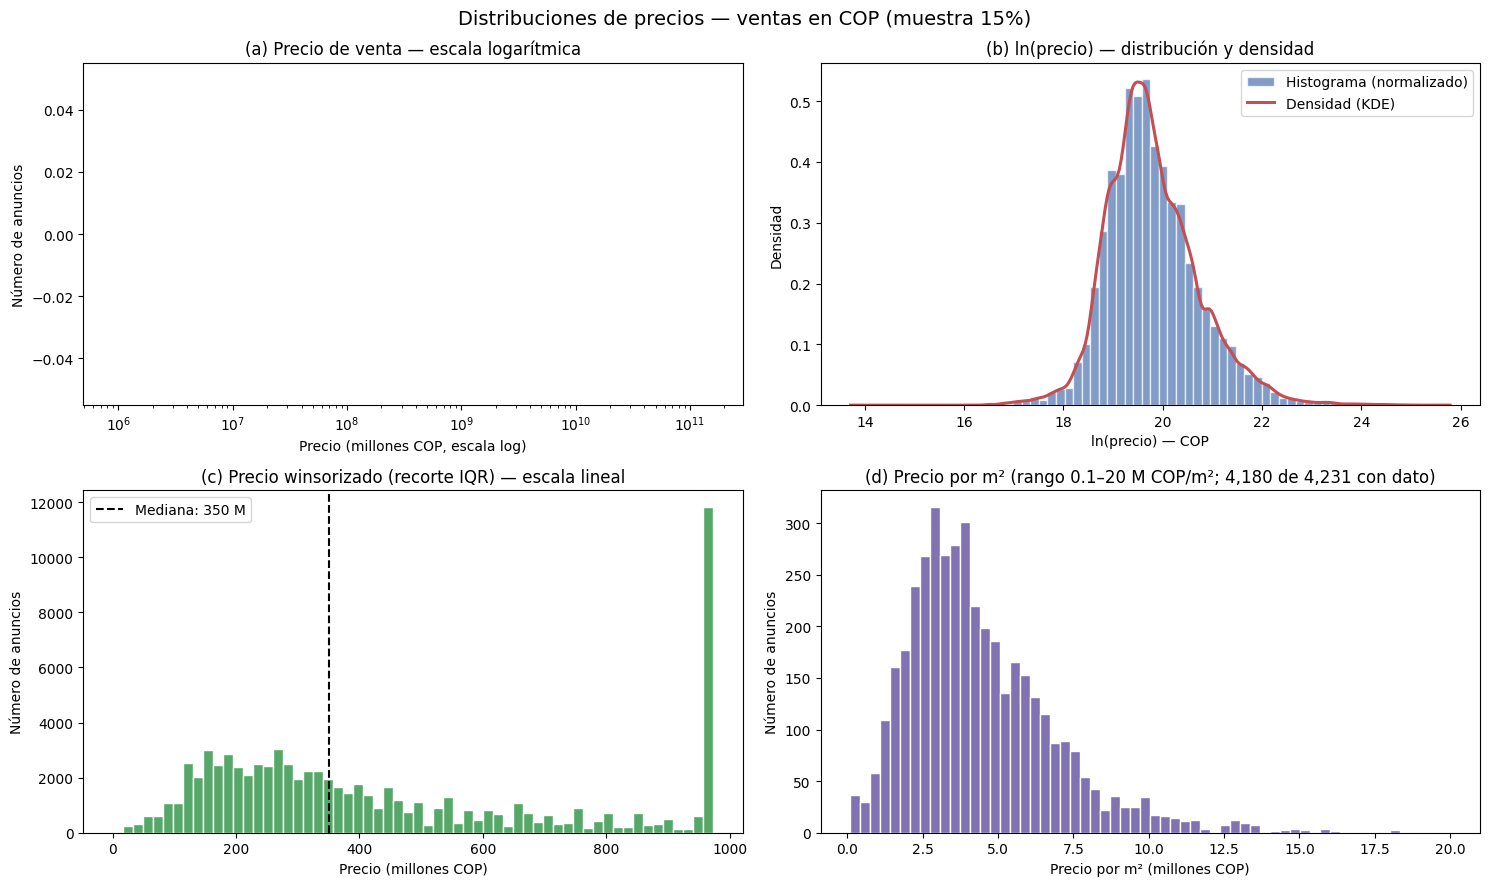

In [0]:
# ==============================================================================
# EDA 2+3 — DISTRIBUCIÓN DE PRECIOS, ASIMETRÍA Y CURTOSIS
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

try:
    from scipy.stats import gaussian_kde
    HAY_KDE = True
except ImportError:
    HAY_KDE = False

# Asimetría y curtosis (exceso) calculadas en Spark sobre TODOS los registros
skw = (m.agg(
    *[F.skewness(c).alias(c) for c in ["price", "precio_log", "precio_m2"]],
    *[F.kurtosis(c).alias(f"k_{c}").alias(f"k_{c}") for c in ["price", "precio_log", "precio_m2"]]
).first().asDict())
filas = [(v, round(skw[v], 2), round(skw[f"k_{v}"], 2)) for v in ["price", "precio_log", "precio_m2"]]
display(spark.createDataFrame(filas, "variable string, asimetria_skewness double, curtosis_exceso double"))

# Muestra para gráficos de distribución
pdf = m.select("price", "precio_log", "price_winsorizado", "precio_m2") \
    .sample(False, 0.15, seed=7).toPandas()
print(f"\nMuestra para gráficos: {len(pdf):,} ventas")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) Precio en escala logarítmica (millones COP)
p = pdf["price"].dropna()
ax = axes[0][0]
bins = np.logspace(np.log10(max(p.min(), 1)), np.log10(p.max()), 80)
ax.hist(p / 1e6, bins=bins, color="#4C72B0", edgecolor="white")
ax.set_xscale("log")
ax.set_title("(a) Precio de venta — escala logarítmica")
ax.set_xlabel("Precio (millones COP, escala log)")
ax.set_ylabel("Número de anuncios")

# (b) ln(precio) con densidad estimada
ax = axes[0][1]
pl = pdf["precio_log"].dropna()
ax.hist(pl, bins=70, density=True, color="#4C72B0", edgecolor="white", alpha=0.7,
        label="Histograma (normalizado)")
if HAY_KDE:
    xs = np.linspace(pl.min(), pl.max(), 300)
    ax.plot(xs, gaussian_kde(pl)(xs), color="#C44E52", lw=2.2, label="Densidad (KDE)")
ax.set_title("(b) ln(precio) — distribución y densidad")
ax.set_xlabel("ln(precio) — COP")
ax.set_ylabel("Densidad")
ax.legend()

# (c) Precio winsorizado (efecto del recorte de atípicos IQR)
ax = axes[1][0]
pw = (pdf["price_winsorizado"].dropna()) / 1e6
ax.hist(pw, bins=60, color="#55A868", edgecolor="white")
ax.axvline(pw.median(), color="black", ls="--", lw=1.5,
           label=f"Mediana: {pw.median():,.0f} M")
ax.set_title("(c) Precio winsorizado (recorte IQR) — escala lineal")
ax.set_xlabel("Precio (millones COP)")
ax.set_ylabel("Número de anuncios")
ax.legend()

# (d) Precio por m² (rango plausible)
ax = axes[1][1]
m2 = pdf["precio_m2"].dropna()
m2_ok = m2[(m2 >= 1e5) & (m2 <= 2e7)]
ax.hist(m2_ok / 1e6, bins=60, color="#8172B2", edgecolor="white")
ax.set_title(f"(d) Precio por m² (rango 0.1–20 M COP/m²; {len(m2_ok):,} de {len(m2):,} con dato)")
ax.set_xlabel("Precio por m² (millones COP)")
ax.set_ylabel("Número de anuncios")

fig.suptitle("Distribuciones de precios — ventas en COP (muestra 15%)", fontsize=14)
plt.tight_layout()
plt.show()

variable,atipicos,pct
price,85136,0.0852
rooms,16399,0.0164
bedrooms,29842,0.0299
bathrooms,57897,0.0579
surface_total,6073,0.0061
surface_covered,6188,0.0062


/home/spark-18f09327-9e7b-41cd-8457-40/.ipykernel/63/command-6479174552036098-1660191582:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=orden, showfliers=True, flierprops=dict(markersize=1.5, alpha=0.3))


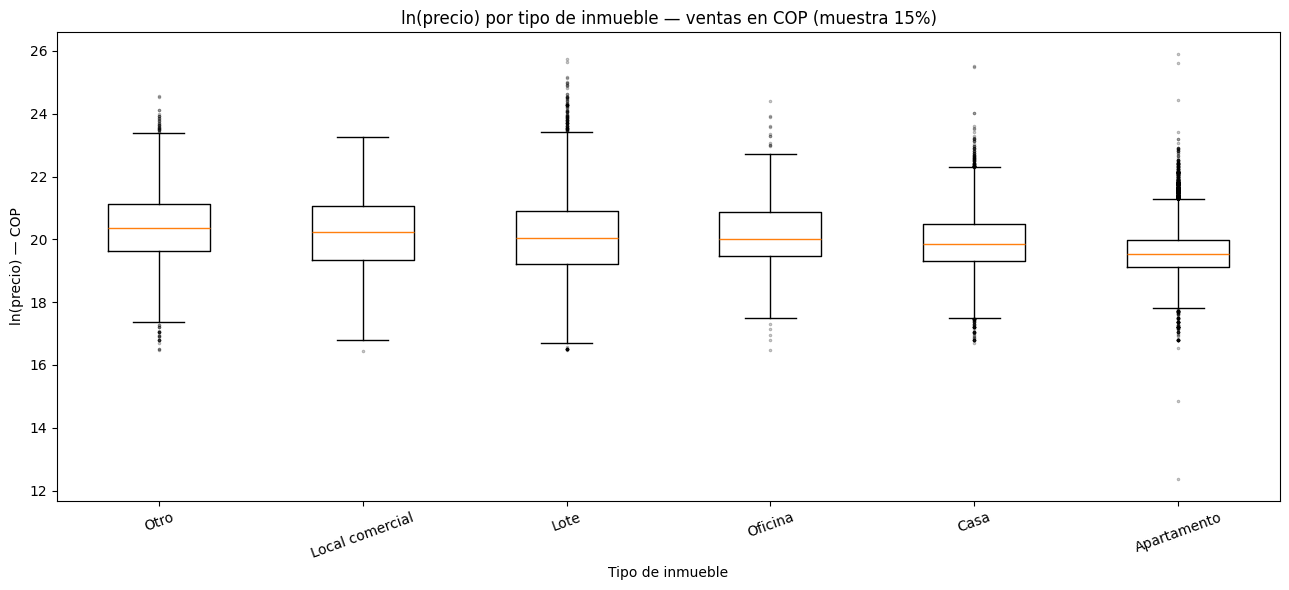

In [0]:
# ==============================================================================
# EDA 4 — VALORES ATÍPICOS (flags IQR de Silver + boxplots por tipo de inmueble)
# ==============================================================================
import matplotlib.pyplot as plt

flags = ["_out_price", "_out_rooms", "_out_bedrooms", "_out_bathrooms",
         "_out_surface_total", "_out_surface_covered"]
# Los flags completos viven en housing_eda (999,454 alineados; incluye arriendos)
n_eda = eda.count()
row = eda.agg(*[F.sum(F.col(f).cast("int")).alias(f) for f in flags]).first().asDict()
display(spark.createDataFrame(
    [(f.replace("_out_", ""), v, round(v / n_eda, 4)) for f, v in row.items()],
    "variable string, atipicos long, pct double"))

# Boxplot de ln(precio) por tipo de inmueble (los 6 tipos más comunes)
top_types = [r["property_type"] for r in m.groupBy("property_type").count()
             .orderBy(F.desc("count")).limit(6).collect()]
bp = (m.filter(F.col("property_type").isin(top_types) & F.col("precio_log").isNotNull())
    .select("property_type", "precio_log").sample(False, 0.15, seed=7).toPandas())
orden = bp.groupby("property_type")["precio_log"].median().sort_values(ascending=False).index
data = [bp[bp["property_type"] == t]["precio_log"].values for t in orden]

fig, ax = plt.subplots(figsize=(13, 6))
ax.boxplot(data, labels=orden, showfliers=True, flierprops=dict(markersize=1.5, alpha=0.3))
ax.set_title("ln(precio) por tipo de inmueble — ventas en COP (muestra 15%)")
ax.set_xlabel("Tipo de inmueble")
ax.set_ylabel("ln(precio) — COP")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

/home/spark-18f09327-9e7b-41cd-8457-40/.ipykernel/63/command-6479174552036099-4117756479:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(pcorr.columns)


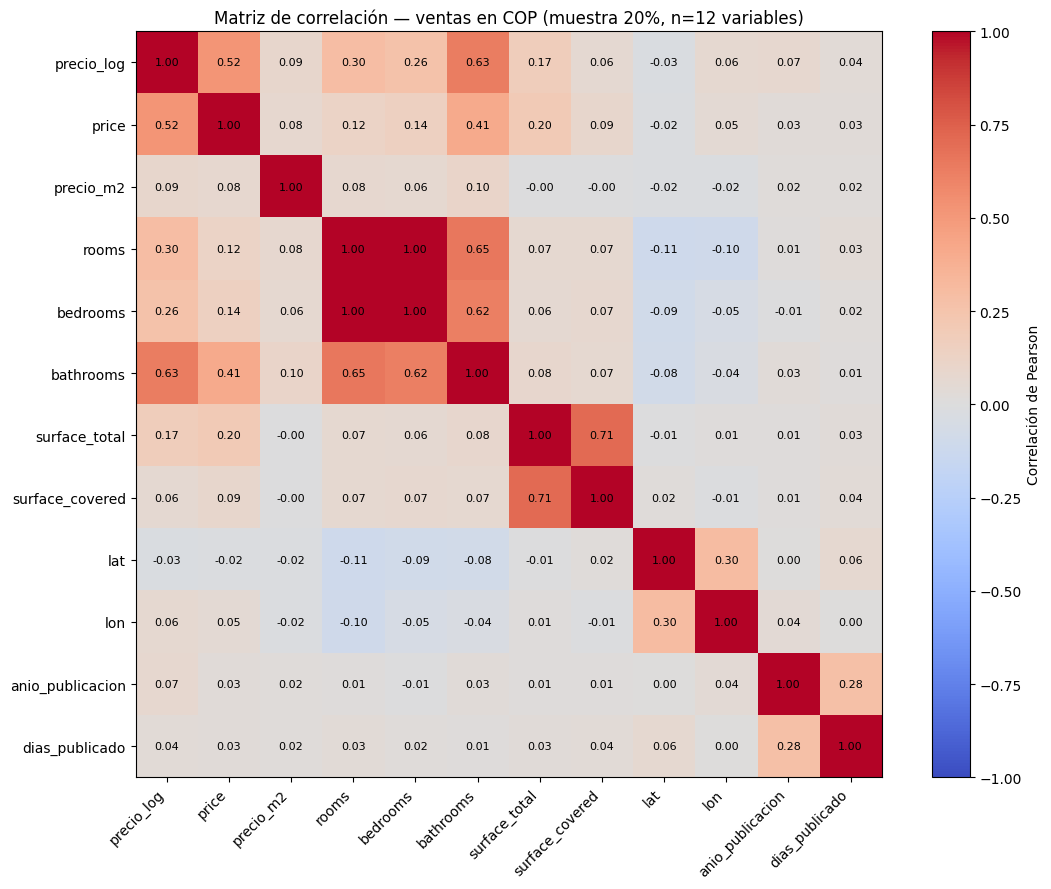


Correlación de cada variable con ln(precio):
  precio_m2: +0.087
  rooms: +0.295
  bedrooms: +0.262
  bathrooms: +0.626
  surface_total: +0.175
  surface_covered: +0.061
  lat: -0.027
  lon: +0.063
  anio_publicacion: +0.070
  dias_publicado: +0.036


In [0]:
# ==============================================================================
# EDA 5 — MATRIZ DE CORRELACIÓN DE VARIABLES NUMÉRICAS
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

CORR_COLS = ["precio_log", "price", "precio_m2", "rooms", "bedrooms", "bathrooms",
             "surface_total", "surface_covered", "lat", "lon",
             "anio_publicacion", "dias_publicado"]
pcorr = m.select(CORR_COLS).sample(False, 0.2, seed=7).toPandas().corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11.5, 9))
im = ax.imshow(pcorr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(pcorr.columns)))
ax.set_xticklabels(pcorr.columns, rotation=45, ha="right")
ax.set_yticklabels(pcorr.columns)
ax.set_yticks(range(len(pcorr.columns)))
for i in range(len(pcorr)):
    for j in range(len(pcorr)):
        ax.text(j, i, f"{pcorr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title(f"Matriz de correlación — ventas en COP (muestra 20%, n={len(pcorr):,} variables)")
plt.tight_layout()
plt.show()

# Correlación con ln(precio) ordenada
print("\nCorrelación de cada variable con ln(precio):")
for c in CORR_COLS:
    if c not in ("precio_log", "price"):
        print(f"  {c}: {pcorr.loc[c, 'precio_log']:+.3f}")

Correlación Pearson ln(precio) vs ln(área construida): +0.744 sobre 27,221 anuncios con área válida (10–1.000 m²)


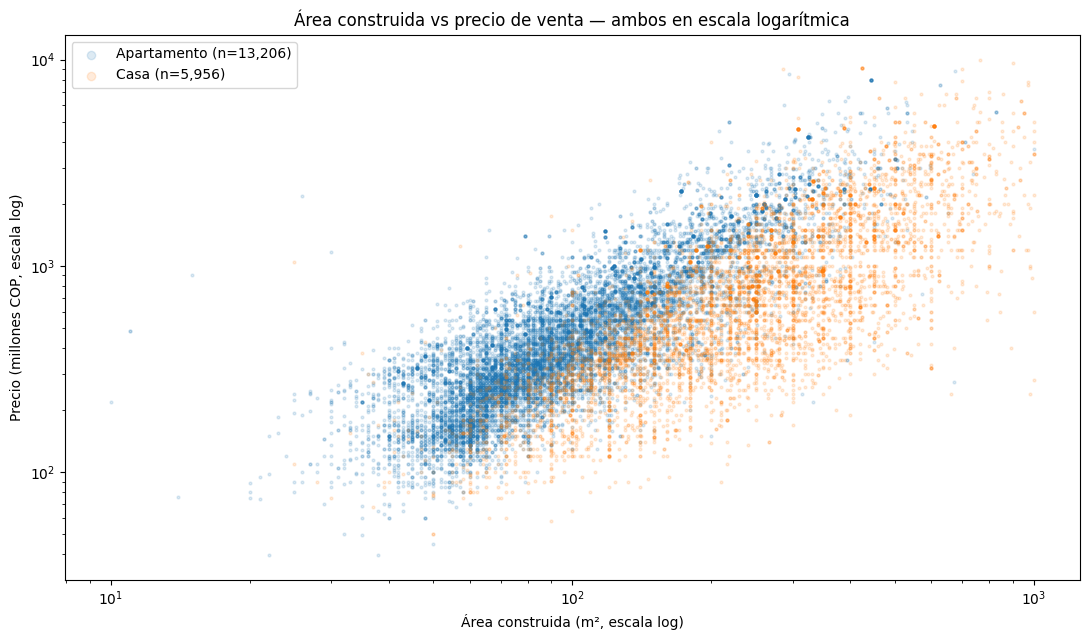

Nota: solo 27,221 de 522,415 ventas (5.2%) reportan área construida.


In [0]:
# ==============================================================================
# EDA 6 — RELACIÓN ENTRE ÁREA Y PRECIO
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

sup = m.filter((F.col("surface_covered") >= 10) & (F.col("surface_covered") <= 1000)
               & F.col("price").isNotNull())
n_sup = sup.count()
r_area = sup.agg(F.corr("precio_log", F.log(F.col("surface_covered"))).alias("r")).first()["r"]
print(f"Correlación Pearson ln(precio) vs ln(área construida): {r_area:+.3f} "
      f"sobre {n_sup:,} anuncios con área válida (10–1.000 m²)")

pdf_sup = sup.select("surface_covered", "price", "property_type").sample(False, 0.8, seed=7).toPandas()
fig, ax = plt.subplots(figsize=(11, 6.5))
for tipo in ["Apartamento", "Casa"]:
    g = pdf_sup[pdf_sup["property_type"] == tipo]
    ax.scatter(g["surface_covered"], g["price"] / 1e6, s=4, alpha=0.15,
               label=f"{tipo} (n={len(g):,})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Área construida vs precio de venta — ambos en escala logarítmica")
ax.set_xlabel("Área construida (m², escala log)")
ax.set_ylabel("Precio (millones COP, escala log)")
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()
print(f"Nota: solo {n_sup:,} de {m.count():,} ventas ({n_sup/m.count():.1%}) reportan área construida.")


Mediana de precio por número de bathrooms (ventas COP, valores 1–8):
+---------+---------+--------------+------+
|bathrooms|registros|precio_mediana|p75   |
+---------+---------+--------------+------+
|1.0      |56634    |1.5E8         |2.4E8 |
|2.0      |182121   |2.65E8        |3.6E8 |
|3.0      |84175    |4.59E8        |6.8E8 |
|4.0      |47297    |7.2E8         |1.2E9 |
|5.0      |22031    |9.9E8         |1.5E9 |
|6.0      |8225     |1.3E9         |2.2E9 |
|7.0      |3270     |1.3E9         |2.2E9 |
|8.0      |1744     |1.5E9         |3.13E9|
+---------+---------+--------------+------+


Mediana de precio por número de bedrooms (ventas COP, valores 1–8):
+--------+---------+--------------+------+
|bedrooms|registros|precio_mediana|p75   |
+--------+---------+--------------+------+
|1.0     |9903     |3.1E8         |4.4E8 |
|2.0     |30115    |2.89E8        |4.8E8 |
|3.0     |98416    |3.5E8         |6.25E8|
|4.0     |25815    |6.5E8         |1.2E9 |
|5.0     |8354     |7.0E8      

/home/spark-18f09327-9e7b-41cd-8457-40/.ipykernel/63/command-6479174552036101-3015422658:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(grupos, labels=etiquetas, flierprops=dict(markersize=1.5, alpha=0.3))
/home/spark-18f09327-9e7b-41cd-8457-40/.ipykernel/63/command-6479174552036101-3015422658:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(grupos, labels=etiquetas, flierprops=dict(markersize=1.5, alpha=0.3))


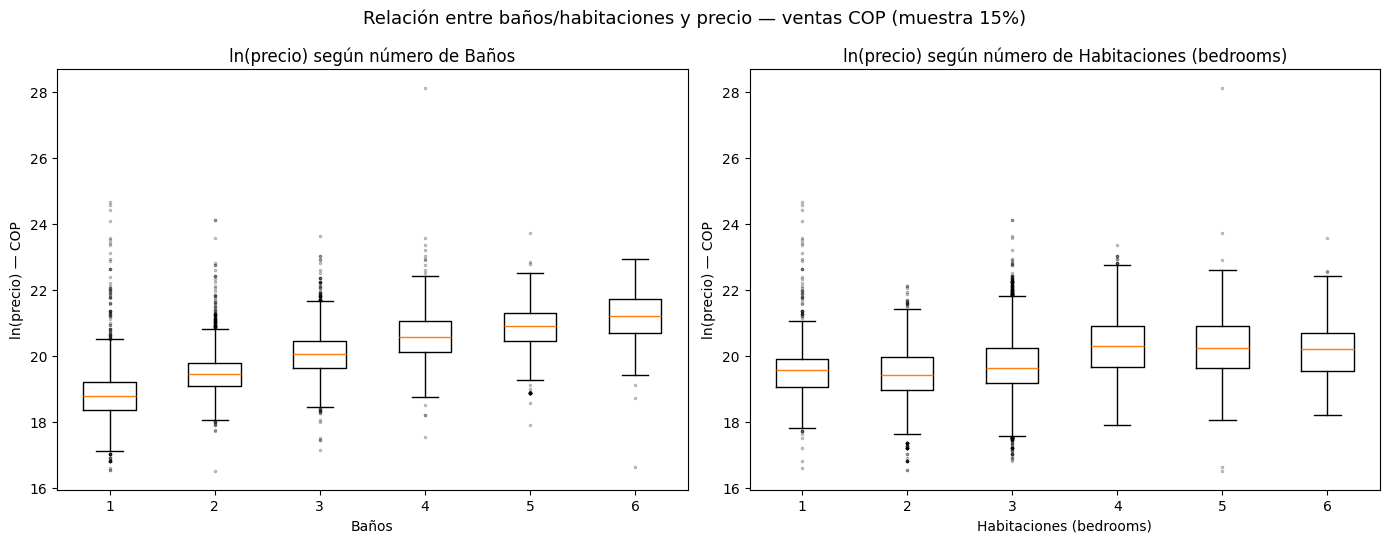

In [0]:
# ==============================================================================
# EDA 7 — HABITACIONES, BAÑOS Y PRECIO
# ==============================================================================
import matplotlib.pyplot as plt

for c in ["bathrooms", "bedrooms", "rooms"]:
    print(f"\nMediana de precio por número de {c} (ventas COP, valores 1–8):")
    (m.filter(F.col(c).between(1, 8)).groupBy(c)
        .agg(F.count("*").alias("registros"),
             F.percentile_approx("price", 0.5).alias("precio_mediana"),
             F.percentile_approx("price", 0.75).alias("p75"))
        .orderBy(c).show(10, truncate=False))

bp = (m.filter(F.col("bathrooms").between(1, 6) & F.col("bedrooms").between(0, 6)
              & F.col("precio_log").isNotNull())
    .select("bathrooms", "bedrooms", "precio_log").sample(False, 0.15, seed=7).toPandas())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, cvar, titulo in [(axes[0], "bathrooms", "Baños"), (axes[1], "bedrooms", "Habitaciones (bedrooms)")]:
    grupos = [bp[bp[cvar] == v]["precio_log"].values for v in sorted(bp[cvar].dropna().unique())]
    etiquetas = [str(int(v)) for v in sorted(bp[cvar].dropna().unique())]
    ax.boxplot(grupos, labels=etiquetas, flierprops=dict(markersize=1.5, alpha=0.3))
    ax.set_title(f"ln(precio) según número de {titulo}")
    ax.set_xlabel(titulo)
    ax.set_ylabel("ln(precio) — COP")
plt.suptitle("Relación entre baños/habitaciones y precio — ventas COP (muestra 15%)", fontsize=13)
plt.tight_layout()
plt.show()

property_type,registros,mediana,mediana_m2
Apartamento,286871,3.0E8,4347826.0869565215
Casa,148329,4.2E8,2906976.7441860465
Lote,36967,5.0E8,600000.0
Otro,35507,7.0E8,2564102.564102564
Oficina,5873,4.95E8,7500000.0
Local comercial,5260,6.0E8,8000000.0
Finca,2906,9.8E8,2714285.714285714
Depósito,626,1.7E9,null
Parqueadero,76,1.5E8,2205882.3529411764


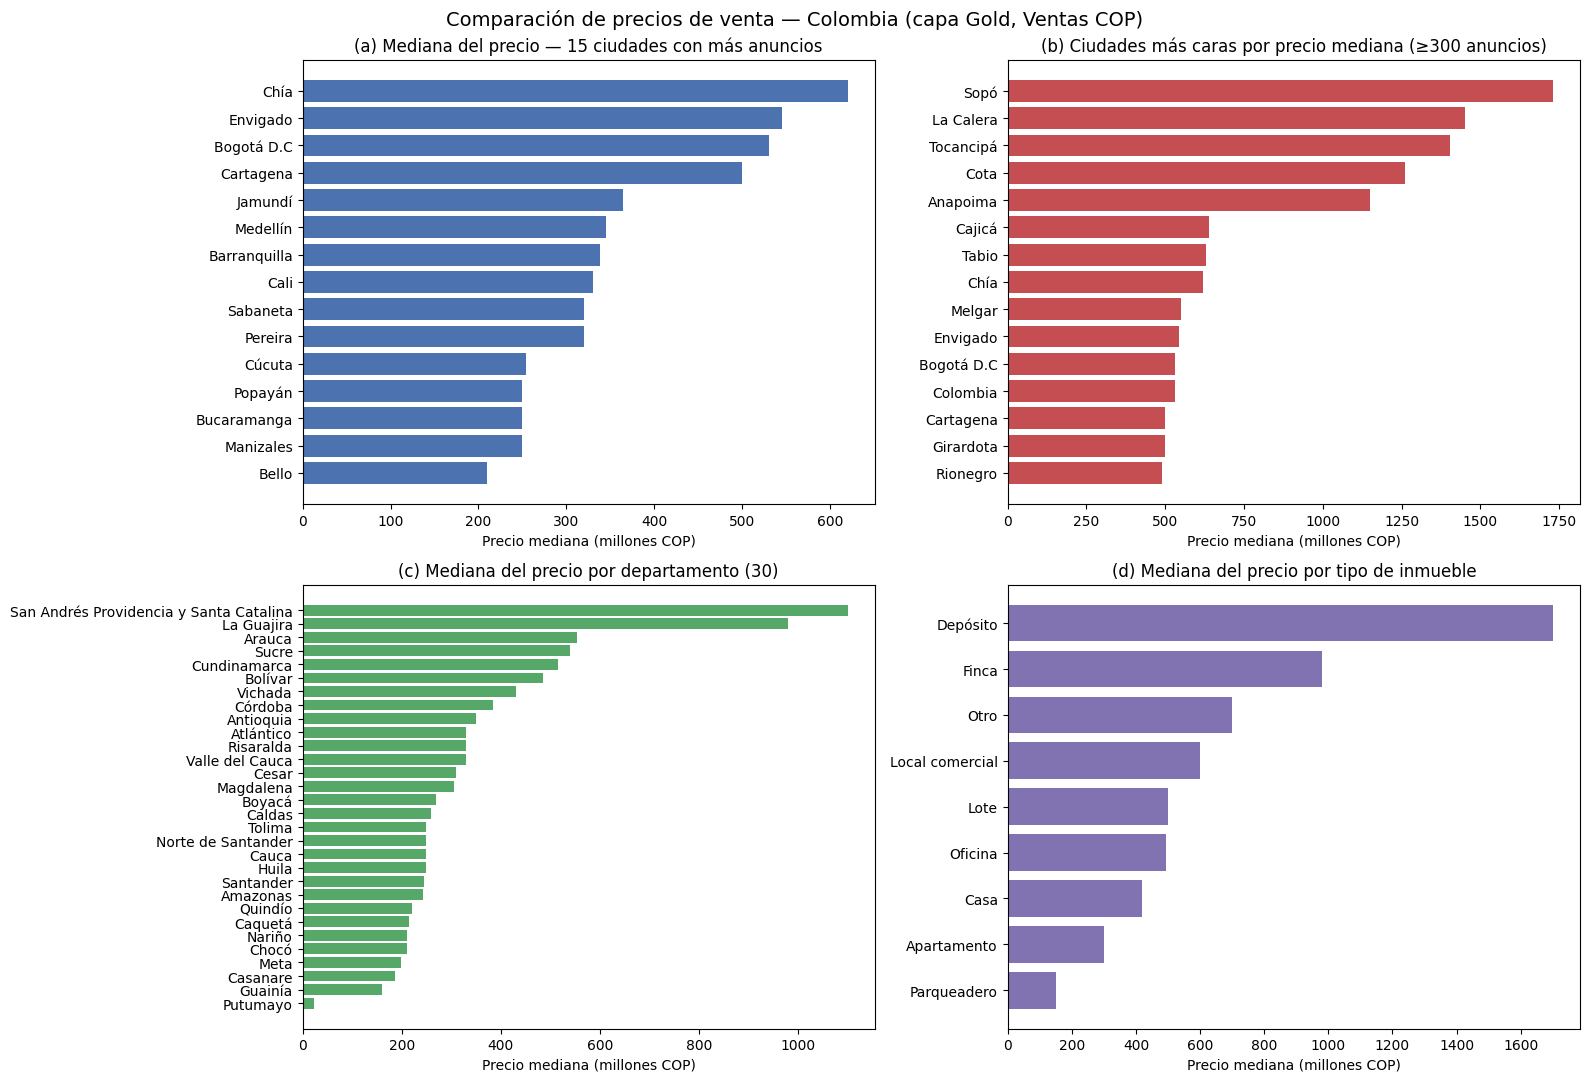

In [0]:
# ==============================================================================
# EDA 8 — PRECIOS POR CIUDAD, DEPARTAMENTO Y TIPO DE INMUEBLE
# ==============================================================================
import matplotlib.pyplot as plt

agg_c = spark.table("housing_colombia.gold.housing_agregado_ciudad").toPandas()
agg_d = spark.table("housing_colombia.gold.housing_agregado_departamento").toPandas()
tipo = (m.groupBy("property_type")
    .agg(F.count("*").alias("registros"),
         F.percentile_approx("price", 0.5).alias("mediana"),
         F.percentile_approx("precio_m2", 0.5).alias("mediana_m2"))
    .orderBy(F.desc("registros")).toPandas())
display(tipo)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# (a) Top-15 ciudades por número de anuncios: mediana de precio
top_n = agg_c.sort_values("registros", ascending=False).head(15).sort_values("precio_mediana")
ax = axes[0][0]
ax.barh(top_n["ciudad"], top_n["precio_mediana"] / 1e6, color="#4C72B0")
ax.set_title("(a) Mediana del precio — 15 ciudades con más anuncios")
ax.set_xlabel("Precio mediana (millones COP)")

# (b) Top-15 ciudades más caras (con al menos 300 anuncios)
caras = agg_c[agg_c["registros"] >= 300].sort_values("precio_mediana", ascending=False).head(15).sort_values("precio_mediana")
ax = axes[0][1]
ax.barh(caras["ciudad"], caras["precio_mediana"] / 1e6, color="#C44E52")
ax.set_title("(b) Ciudades más caras por precio mediana (≥300 anuncios)")
ax.set_xlabel("Precio mediana (millones COP)")

# (c) Departamentos: mediana de precio
ag_d = agg_d.sort_values("precio_mediana")
ax = axes[1][0]
ax.barh(ag_d["departamento"], ag_d["precio_mediana"] / 1e6, color="#55A868")
ax.set_title("(c) Mediana del precio por departamento (30)")
ax.set_xlabel("Precio mediana (millones COP)")

# (d) Mediana de precio por tipo de inmueble
ag_t = tipo.sort_values("mediana")
ax = axes[1][1]
ax.barh(ag_t["property_type"], ag_t["mediana"] / 1e6, color="#8172B2")
ax.set_title("(d) Mediana del precio por tipo de inmueble")
ax.set_xlabel("Precio mediana (millones COP)")

fig.suptitle("Comparación de precios de venta — Colombia (capa Gold, Ventas COP)", fontsize=14)
plt.tight_layout()
plt.show()

Anuncios con precio/m² en rango plausible (0.1–20 M COP/m²): 27,890 de 522,415 ventas (5.3%)
Mediana: 3.94 M COP/m² | Promedio: 4.49 M COP/m²


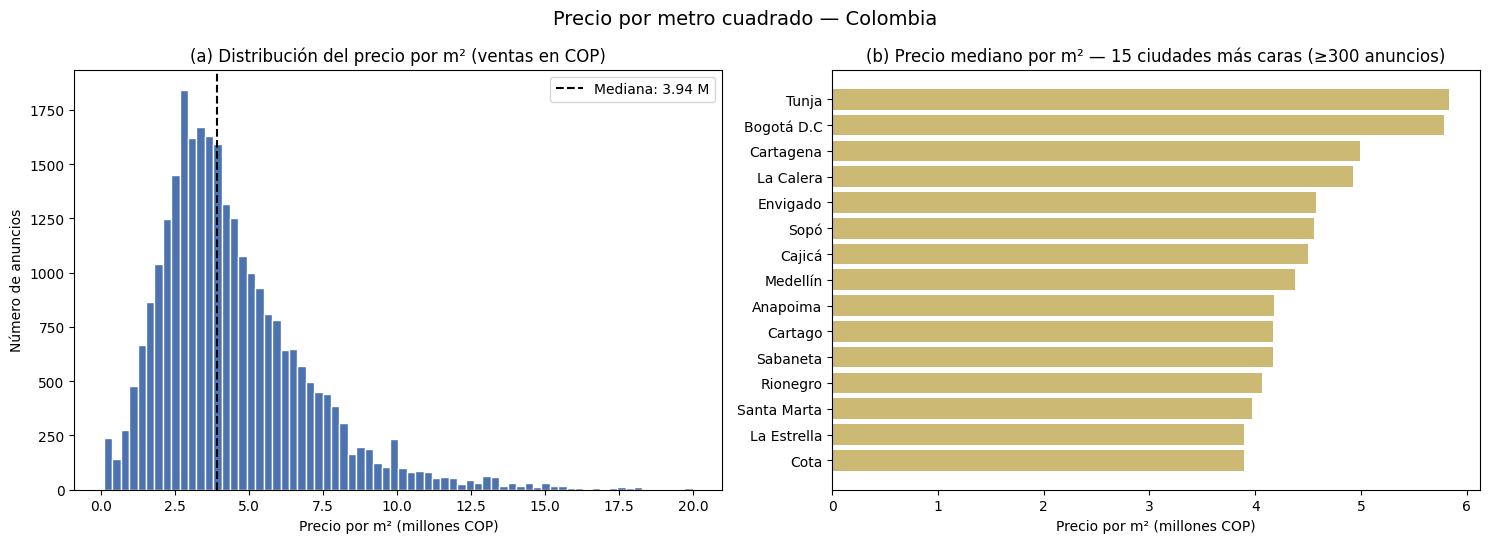

In [0]:
# ==============================================================================
# EDA 9 — PRECIO POR METRO CUADRADO
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

m2_df = m.select("precio_m2").filter(F.col("precio_m2").isNotNull() &
                                     F.col("precio_m2").between(1e5, 2e7)).toPandas()
print(f"Anuncios con precio/m² en rango plausible (0.1–20 M COP/m²): {len(m2_df):,} "
      f"de {m.count():,} ventas ({len(m2_df)/m.count():.1%})")
print(f"Mediana: {m2_df['precio_m2'].median()/1e6:.2f} M COP/m² | "
      f"Promedio: {m2_df['precio_m2'].mean()/1e6:.2f} M COP/m²")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.hist(m2_df["precio_m2"] / 1e6, bins=70, color="#4C72B0", edgecolor="white")
ax.axvline(m2_df["precio_m2"].median() / 1e6, color="black", ls="--",
           label=f"Mediana: {m2_df['precio_m2'].median()/1e6:.2f} M")
ax.set_title("(a) Distribución del precio por m² (ventas en COP)")
ax.set_xlabel("Precio por m² (millones COP)")
ax.set_ylabel("Número de anuncios")
ax.legend()

m2_ciudades = agg_c[agg_c["registros"] >= 300].sort_values("precio_m2_mediana", ascending=False).head(15).sort_values("precio_m2_mediana")
ax = axes[1]
ax.barh(m2_ciudades["ciudad"], m2_ciudades["precio_m2_mediana"] / 1e6, color="#CCB974")
ax.set_title("(b) Precio mediano por m² — 15 ciudades más caras (≥300 anuncios)")
ax.set_xlabel("Precio por m² (millones COP)")

fig.suptitle("Precio por metro cuadrado — Colombia", fontsize=14)
plt.tight_layout()
plt.show()

Muestra geográfica: 58,965 ventas con coordenadas


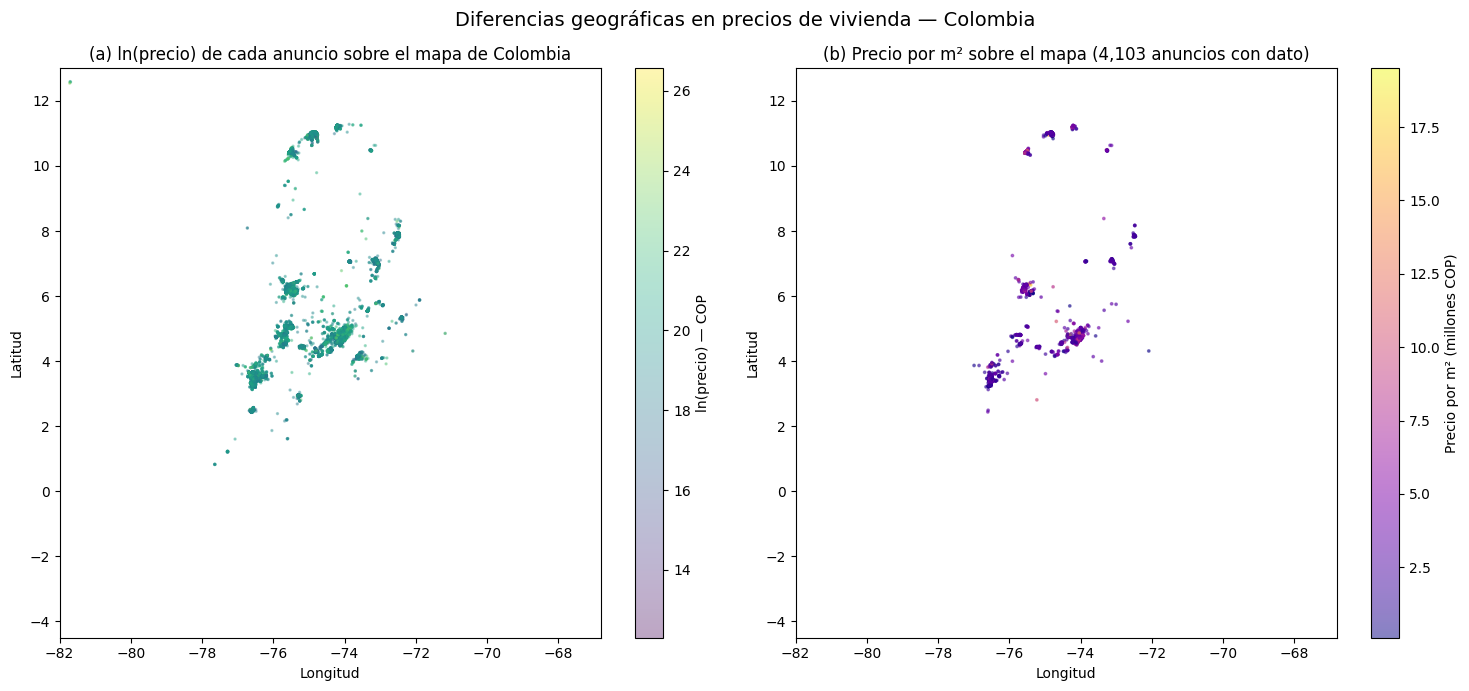

In [0]:
# ==============================================================================
# EDA 10 — PATRONES GEOGRÁFICOS: PRECIO SOBRE LAS COORDENADAS DE COLOMBIA
# ==============================================================================
import matplotlib.pyplot as plt

geo = (m.filter(F.col("lat").isNotNull() & F.col("lon").isNotNull() & F.col("precio_log").isNotNull())
    .select("lat", "lon", "precio_log", "precio_m2")
    .sample(False, 0.15, seed=7).toPandas())
print(f"Muestra geográfica: {len(geo):,} ventas con coordenadas")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

ax = axes[0]
sc = ax.scatter(geo["lon"], geo["lat"], c=geo["precio_log"], cmap="viridis",
                s=2, alpha=0.35)
ax.set_xlim(-82, -66.8)
ax.set_ylim(-4.5, 13)
fig.colorbar(sc, ax=ax, label="ln(precio) — COP")
ax.set_title("(a) ln(precio) de cada anuncio sobre el mapa de Colombia")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax = axes[1]
g2 = geo[geo["precio_m2"].between(1e5, 2e7)]
sc = ax.scatter(g2["lon"], g2["lat"], c=g2["precio_m2"] / 1e6, cmap="plasma",
                s=3, alpha=0.5)
ax.set_xlim(-82, -66.8)
ax.set_ylim(-4.5, 13)
fig.colorbar(sc, ax=ax, label="Precio por m² (millones COP)")
ax.set_title(f"(b) Precio por m² sobre el mapa ({len(g2):,} anuncios con dato)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

fig.suptitle("Diferencias geográficas en precios de vivienda — Colombia", fontsize=14)
plt.tight_layout()
plt.show()

## Conclusiones del EDA — patrones identificados

**1. Distribución del precio.** El precio de venta (522.415 anuncios COP) tiene mediana de **350 M COP**, pero media de **711 M** y máximo de 1,6×10¹² COP: la cola derecha es extrema (asimetría +257, curtosis +119.997). En cambio, **ln(precio) es prácticamente normal** (asimetría +0,67, curtosis +1,64): se confirma el logaritmo como escala de modelado. Venta y arriendo son universos distintos (mediana 350 M vs 1,5 M COP).

**2. Variables con mayor poder explicativo.**
* **Baños** es la variable estructural más informativa: correlación **+0,626** con ln(precio) y mediana de precio creciente de forma casi monótona: 150 M (1 baño) → 265 M (2) → 459 M (3) → 720 M (4) → 990 M (5) → 1.300 M (6+). Además tiene la mejor cobertura (78%).
* **Área construida**: correlación ln-ln de **+0,744** (la más alta), pero solo 5,2% de los anuncios la reportan — muy predictiva donde existe.
* **Habitaciones/ambientes**: correlación +0,295/+0,262; la mediana sube hasta 4–5 espacios (700–785 M) y se aplana.
* **Tipo de inmueble**: Apartamento 300 M vs Casa 420 M vs Finca 980 M y Depósito 1.700 M de mediana.
* **Geografía**: Bogotá D.C (530 M) y su zona de influencia (Chía 620 M, Envigado 545 M) superan a Medellín (345 M) y Cali (330 M). En precio por m²: Bogotá 5,78 M lidera, seguida de Envigado 4,57 M y Medellín 4,38 M; Cali 2,93 M. Antioquia+Cundinamarca concentran ~55% de los anuncios (y el top-5 de departamentos, 83%).
* lat/lon crudas casi no correlacionan linealmente (−0,03 / +0,06): su valor es **no lineal** (efecto ciudad/zona), no continuo.

**3. Atípicos.** 8,5% de precios fuera de IQR (85.136 de 999.454 registros alineados; boxplot por tipo en EDA 4); disponibles los flags `_out_*` y `price_winsorizado` para el modelo.

**4. Limitaciones de datos.** Superficie reportada solo en 5–6% de anuncios; precio/m² disponible en 5,3% (mediana **3,94 M COP/m²**); `dias_publicado` contiene extremos imposibles (máx ~2,9 M de días) que conviene revisar en Silver; el dataset cubre 2020–2021.

**Recomendación para el modelo predictivo:** target `precio_log`; predictores `bathrooms`, `property_type`, `ciudad`/`departamento` (+ lat/lon), `rooms`/`bedrooms`, superficies cuando existan, flags `tiene_*` y `anio_publicacion`; imputación de baños por tipo+ciudad.

## Ajuste de distribuciones de probabilidad al precio

**Hipótesis a comprobar:** los precios (positivos, asimétricos a la derecha) podrían seguir una distribución **Gamma**.

Metodología — no se asume que Gamma sea la mejor; se compara contra **Lognormal, Weibull y Exponencial** con evidencia:

1. Análisis de la distribución **empírica** (momentos, cuantiles, cola).
2. Ajuste por **máxima verosimilitud** de cada candidata (shape / loc / scale).
3. Comparación por **log-verosimilitud, AIC, BIC** y distancia **Kolmogorov-Smirnov**.
4. Pruebas de **bondad de ajuste** (KS naivo, chi-cuadrado, bootstrap paramétrico) **interpretando sus limitaciones** (n enorme, parámetros estimados de los mismos datos, no-i.i.d. por ciudad/tipo).

* Universo: ventas en COP (`gold.housing_model_features`, sin mezclar arriendos).
* Unidad de trabajo: **millones COP** (por estabilidad numérica). Los parámetros se guardan en Gold junto con su unidad.

In [0]:
# ==============================================================================
# DIST 1 — DISTRIBUCIÓN EMPÍRICA DE LOS PRECIOS DE VENTA
# ==============================================================================
from pyspark.sql import functions as F
import numpy as np
import pandas as pd

m = spark.table("housing_colombia.gold.housing_model_features")
pdf_p = m.select("price", "_out_price").toPandas()

x = (pdf_p["price"] / 1e6).dropna()                      # precios en millones COP
x_sin_atipicos = (pdf_p.loc[pdf_p["_out_price"] == False, "price"] / 1e6).dropna()  # noqa: E712
x_ln = np.log(pdf_p["price"].dropna())                    # ln(precio COP)

print(f"n = {len(x):,} ventas | unidad: millones COP | sin atípicos IQR: {len(x_sin_atipicos):,}")
print(f"Media: {x.mean():,.1f} | Mediana: {x.median():,.1f} | Desviación: {x.std():,.1f}")
print(f"Asimetría: {x.skew():.2f} | Curtosis (exceso): {x.kurt():.2f}")
print(f"ln(precio): media {x_ln.mean():.3f} | desv {x_ln.std():.3f} | "
      f"asimetría {x_ln.skew():.3f} | curtosis {x_ln.kurt():.3f}")

qs = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.0]
tabla_q = pd.DataFrame({
    "cuantil": [f"{q*100:g}%" for q in qs],
    "precio_medios": [round(float(x.quantile(q)), 2) for q in qs]})
display(spark.createDataFrame(tabla_q))
print(f"\nCola derecha: p99 = {x.quantile(.99):,.0f} M vs mediana {x.median():,.0f} M | "
      f"máximo = {x.max():,.0f} M ({x.max()/x.median():,.0f}x la mediana)")

n = 522,415 ventas | unidad: millones COP | sin atípicos IQR: 444,113
Media: 710.8 | Mediana: 350.0 | Desviación: 3,207.1
Asimetría: 256.99 | Curtosis (exceso): 119998.19
ln(precio): media 19.795 | desv 0.923 | asimetría 0.666 | curtosis 1.643


cuantil,precio_medios
1%,55.0
5%,115.0
10%,140.0
25%,220.0
50%,350.0
75%,660.0
90%,1320.0
95%,2090.0
99%,5330.64
99.9%,25000.0



Cola derecha: p99 = 5,331 M vs mediana 350 M | máximo = 1,600,000 M (4,571x la mediana)


In [0]:
# ==============================================================================
# DIST 2 — AJUSTE MLE DE LAS DISTRIBUCIONES CANDIDATAS (Gamma, Lognormal, Weibull, Exponencial)
# ==============================================================================
from scipy import stats as st
import numpy as np
import pandas as pd

ajustes = {}   # nombre -> (distribucion, params, k_params, fit_kwargs)

# --- Gamma: se estiman shape, location y scale (loc libre; si degenera, se fija loc=0)
p_gamma = st.gamma.fit(x)                       # MLE con los 3 parámetros libres
ks_g = st.kstest(x, st.gamma.cdf, args=p_gamma).statistic
gamma_loc_libre = (np.isfinite(st.gamma.logpdf(x, *p_gamma).sum()) and p_gamma[1] >= 0
                   and p_gamma[0] >= 1e-3 and ks_g < 0.5)
if not gamma_loc_libre:
    print(f"Gamma loc-libre DEGENERÓ (shape={p_gamma[0]:.3g}, loc={p_gamma[1]:.3g}, "
          f"scale={p_gamma[2]:.3g}, KS D={ks_g:.3f}) -> se reajusta fijando loc=0")
    p_gamma = st.gamma.fit(x, floc=0)
ajustes["Gamma"] = (st.gamma, p_gamma, 3 if gamma_loc_libre else 2, {} if gamma_loc_libre else {"floc": 0})
print(f"Gamma: loc libre = {gamma_loc_libre} -> shape={p_gamma[0]:.6g}, loc={p_gamma[1]:.6g}, scale={p_gamma[2]:.6g}")

ajustes["Lognormal"] = (st.lognorm, st.lognorm.fit(x, floc=0), 2, {"floc": 0})
ajustes["Weibull"] = (st.weibull_min, st.weibull_min.fit(x, floc=0), 2, {"floc": 0})
ajustes["Exponencial"] = (st.expon, st.expon.fit(x, floc=0), 1, {"floc": 0})

print("\nParámetros ajustados (millones COP):")
NOMBRES_P = {"Gamma": ("shape a", "loc", "scale"), "Lognormal": ("shape s", "loc", "scale"),
             "Weibull": ("shape c", "loc", "scale"), "Exponencial": ("loc", "scale")}
for nombre, (dist, params, k, kw) in ajustes.items():
    print("  " + nombre + ": " + ", ".join(f"{n}={v:.6g}" for n, v in zip(NOMBRES_P[nombre], params)))

# --- Comparación: log-verosimilitud, AIC, BIC, distancia KS ---
rows = []
for nombre, (dist, params, k, kw) in ajustes.items():
    ll = dist.logpdf(x, *params).sum()
    assert np.isfinite(ll), f"{nombre}: log-verosimilitud no finita"
    ks = st.kstest(x, dist.cdf, args=params)
    rows.append({"distribucion": nombre, "k_params": k, "log_verosimilitud": ll,
                 "AIC": 2 * k - 2 * ll, "BIC": k * np.log(len(x)) - 2 * ll,
                 "KS_estadistico": ks.statistic, "KS_p_naivo": ks.pvalue})
comp = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
comp["delta_AIC"] = comp["AIC"] - comp["AIC"].min()
comp["ranking_AIC"] = range(1, len(comp) + 1)
display(spark.createDataFrame(comp.round(4)))

# --- Sensibilidad: ¿el orden cambia si se excluyen los atípicos IQR? ---
print(f"\nSensibilidad excluyendo atípicos IQR de precio (n={len(x_sin_atipicos):,}, loc=0):")
sens = []
for nombre in ["Gamma", "Lognormal", "Weibull"]:
    dist, _, k, _ = ajustes[nombre]
    p_ = dist.fit(x_sin_atipicos, floc=0)
    ll_ = dist.logpdf(x_sin_atipicos, *p_).sum()
    sens.append({"distribucion": nombre, "log_verosimilitud": ll_, "AIC": 2 * k - 2 * ll_})
display(spark.createDataFrame(pd.DataFrame(sens).round(2)))

Gamma loc-libre DEGENERÓ (shape=1.54e-06, loc=0.0011, scale=14.7, KS D=1.000) -> se reajusta fijando loc=0
Gamma: loc libre = False -> shape=0.984965, loc=0, scale=721.64

Parámetros ajustados (millones COP):
  Gamma: shape a=0.984965, loc=0, scale=721.64
  Lognormal: shape s=0.922818, loc=0, scale=395.166
  Weibull: shape c=0.872245, loc=0, scale=640.877
  Exponencial: loc=0, scale=710.791


distribucion,k_params,log_verosimilitud,AIC,BIC,KS_estadistico,KS_p_naivo,delta_AIC,ranking_AIC
Lognormal,2,-3822991.0798,7645986.1597,7646008.4921,0.0668,0.0,0.0,1
Weibull,2,-3937832.9954,7875669.9909,7875692.3233,0.1512,0.0,229683.8312,2
Gamma,2,-3952750.5171,7905505.0343,7905527.3667,0.1537,0.0,259518.8746,3
Exponencial,1,-3952789.4427,7905580.8853,7905592.0516,0.1558,0.0,259594.7257,4



Sensibilidad excluyendo atípicos IQR de precio (n=444,113, loc=0):


distribucion,log_verosimilitud,AIC
Gamma,-2955996.2,5911996.41
Lognormal,-2964699.65,5929403.3
Weibull,-2962638.83,5925281.65


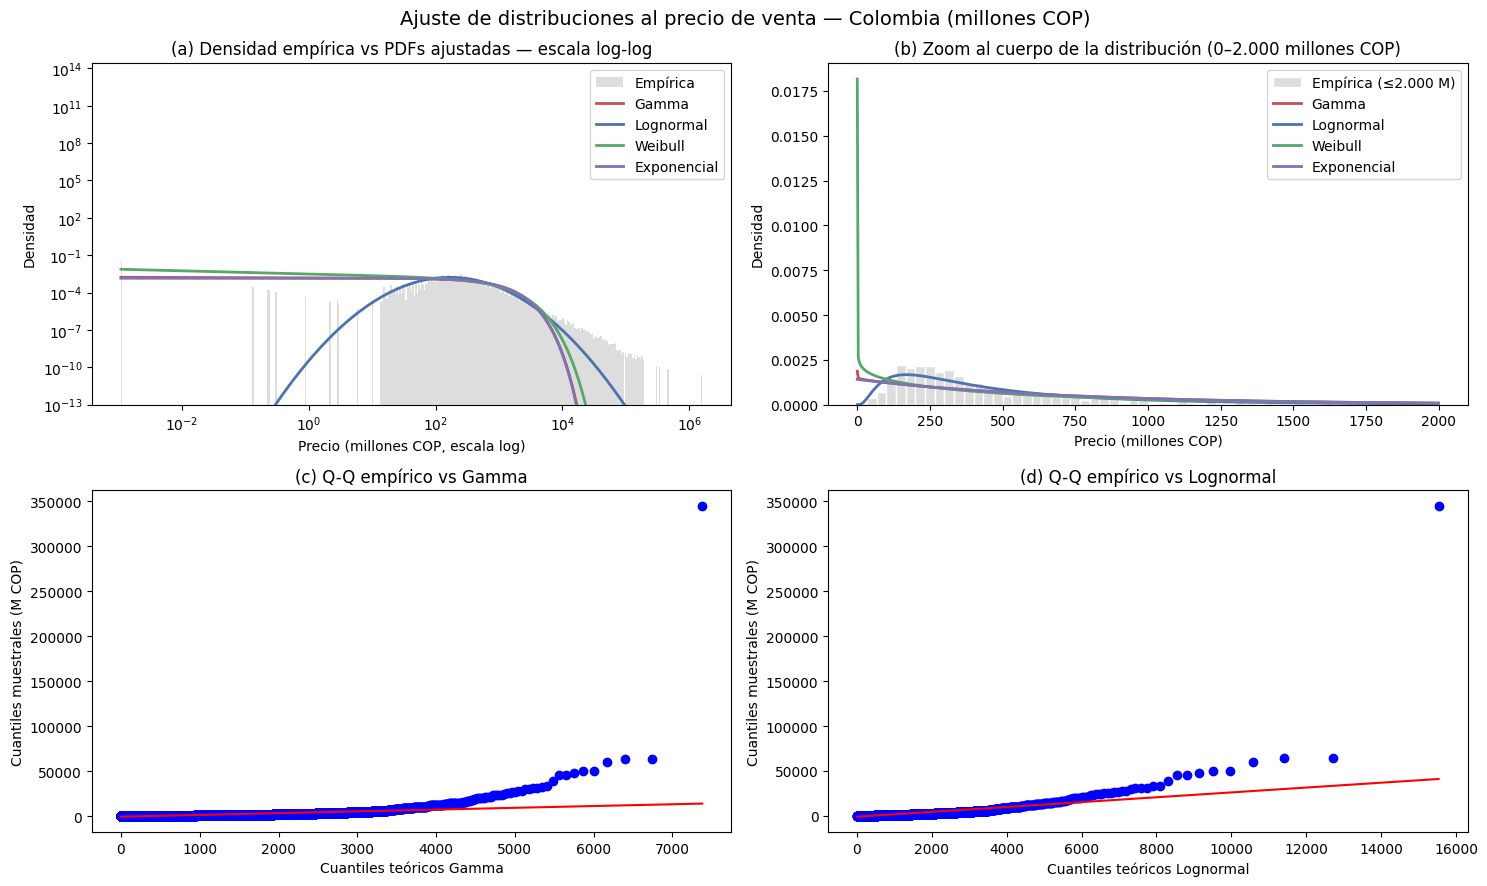

In [0]:
# ==============================================================================
# DIST 3 — HISTOGRAMA NORMALIZADO + PDFs ESTIMADAS (Gamma y candidatas) Y Q-Q PLOTS
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats as st

CANDIDATAS = ["Gamma", "Lognormal", "Weibull", "Exponencial"]
COLORES = {"Gamma": "#C44E52", "Lognormal": "#4C72B0", "Weibull": "#55A868", "Exponencial": "#8172B2"}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) Densidad empírica en eje logarítmico con las PDFs superpuestas
ax = axes[0][0]
xs_log = np.logspace(np.log10(max(x.min(), 1e-3)), np.log10(x.max()), 400)
ax.hist(x, bins=xs_log, density=True, color="#DDDDDD", edgecolor="none", label="Empírica")
for nombre in CANDIDATAS:
    dist, params, _, _ = ajustes[nombre]
    ax.plot(xs_log, dist.pdf(xs_log, *params), color=COLORES[nombre], lw=2, label=nombre)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(bottom=1e-13)
ax.set_title("(a) Densidad empírica vs PDFs ajustadas — escala log-log")
ax.set_xlabel("Precio (millones COP, escala log)"); ax.set_ylabel("Densidad")
ax.legend()

# (b) Zoom en el cuerpo de la distribución (0–2.000 M), escala lineal
ax = axes[0][1]
rango = x[(x > 0) & (x <= 2000)]
bins_lin = np.linspace(0, 2000, 61)
ax.hist(rango, bins=bins_lin, density=True, color="#DDDDDD", edgecolor="white", label="Empírica (≤2.000 M)")
xs_lin = np.linspace(1e-6, 2000, 600)
for nombre in CANDIDATAS:
    dist, params, _, _ = ajustes[nombre]
    ax.plot(xs_lin, dist.pdf(xs_lin, *params), color=COLORES[nombre], lw=2, label=nombre)
ax.set_title("(b) Zoom al cuerpo de la distribución (0–2.000 millones COP)")
ax.set_xlabel("Precio (millones COP)"); ax.set_ylabel("Densidad")
ax.legend()

# (c) Q-Q plot Gamma  |  (d) Q-Q plot Lognormal  (muestra de 20.000)
xs_q = x.sample(20000, random_state=7).values
st.probplot(xs_q, dist="gamma", sparams=ajustes["Gamma"][1], plot=axes[1][0])
axes[1][0].set_title("(c) Q-Q empírico vs Gamma")
axes[1][0].set_xlabel("Cuantiles teóricos Gamma"); axes[1][0].set_ylabel("Cuantiles muestrales (M COP)")
st.probplot(xs_q, dist="lognorm", sparams=ajustes["Lognormal"], plot=axes[1][1]) if False else st.probplot(xs_q, dist="lognorm", sparams=ajustes["Lognormal"][1], plot=axes[1][1])
axes[1][1].set_title("(d) Q-Q empírico vs Lognormal")
axes[1][1].set_xlabel("Cuantiles teóricos Lognormal"); axes[1][1].set_ylabel("Cuantiles muestrales (M COP)")

fig.suptitle("Ajuste de distribuciones al precio de venta — Colombia (millones COP)", fontsize=14)
plt.tight_layout()
plt.show()

In [0]:
# ==============================================================================
# DIST 4 — PRUEBAS DE BONDAD DE AJUSTE (con interpretación de limitaciones)
# ==============================================================================
from scipy import stats as st
import numpy as np

n_total = len(x)
print(f"== 1) Kolmogorov-Smirnov (n={n_total:,}) con parámetros ESTIMADOS ==")
for nombre, (dist, params, k, kw) in ajustes.items():
    ks = st.kstest(x, dist.cdf, args=params)
    print(f"  {nombre}: D = {ks.statistic:.5f} | p-valor naivo = {ks.pvalue:.3g} "
          f"(INVÁLIDO: los parámetros salen de los mismos datos; además, con n enorme cualquier desviación minúscula da p ≈ 0)")

print("\n== 2) Chi-cuadrado por bins (fusión de esperados < 5) ==")
def prueba_chi2(dist, params, datos, nbins=60):
    cortes = np.quantile(datos, np.linspace(0, 1, nbins + 1))
    cortes[0] = datos.min() - 1; cortes[-1] = datos.max() + 1
    esperado = np.diff(dist.cdf(cortes, *params)) * len(datos)
    observado = np.histogram(datos, bins=cortes)[0]
    o2, e2, acc_o, acc_e = [], [], 0, 0
    for o, e in zip(observado, esperado):
        acc_o += o; acc_e += e
        if acc_e >= 5:
            o2.append(acc_o); e2.append(acc_e); acc_o = acc_e = 0
    if acc_e > 0 and o2:
        o2[-1] += acc_o; e2[-1] += acc_e
    o2, e2 = np.array(o2), np.array(e2)
    stat = ((o2 - e2) ** 2 / e2).sum()
    df = len(o2) - 1 - len(params)
    return stat, df, st.chi2.sf(stat, df), len(o2)

for nombre in ["Gamma", "Lognormal", "Weibull"]:
    dist, params, k, kw = ajustes[nombre]
    stat, df, p, nb = prueba_chi2(dist, params, x)
    print(f"  {nombre}: chi2 = {stat:,.0f} | df = {df} ({nb} bins) | p = {p:.3g}")

print("\n== 3) Jarque-Bera sobre ln(precio) — ilustración del problema del n enorme ==")
jb = st.jarque_bera(x_ln)
print(f"  JB = {jb.statistic:,.1f} | p = {jb.pvalue:.3g} — con curtosis +1,6 de exceso el test rechaza normalidad, "
      "aunque ln(precio) es visualmente casi normal")

print("\n== 4) KS con p-valor por BOOTSTRAP PARAMÉTRICO (válido: reajusta en cada simulación) ==")
p_boot = {}
def ks_bootstrap(nombre, n_sub=2000, nsim=200, seed=7):
    dist, params, k, kw = ajustes[nombre]
    rng = np.random.default_rng(seed)
    def _fit_seguro(datos):
        try:
            return dist.fit(datos, **kw)
        except Exception:
            return dist.fit(datos, floc=0)
    sub = rng.choice(x.values, size=n_sub, replace=False)
    p_sub = _fit_seguro(sub)
    d_obs = st.kstest(sub, dist.cdf, args=p_sub).statistic
    mayores = 0
    for _ in range(nsim):
        sim = dist.rvs(*p_sub, size=n_sub, random_state=rng)
        p_sim = _fit_seguro(sim)
        if st.kstest(sim, dist.cdf, args=p_sim).statistic >= d_obs:
            mayores += 1
    return d_obs, (mayores + 1) / (nsim + 1)

for nombre in ["Gamma", "Lognormal", "Weibull"]:
    d_obs, p = ks_bootstrap(nombre)
    p_boot[nombre] = p
    print(f"  {nombre}: D (submuestra n=2.000) = {d_obs:.4f} | p bootstrap = {p:.3f} "
        f"({'SE RECHAZA' if p < 0.05 else 'NO se rechaza'} ajuste a nivel 5%)")

print("\n== Limitaciones e interpretación ==")
print("* KS naivo: parámetros estimados de los mismos datos -> p-valor inválido (anti-conservador). Por eso se acompaña del bootstrap.")
print("* Con n = 522.415, la potencia es tal que p-valores ≈ 0 NO implican diferencia práctica relevante: pesan más AIC/BIC, D de KS y gráficos.")
print("* Chi-cuadrado: resultado depende del número y forma de los bins; se usa solo como complemento.")
print("* i.i.d. no se cumple del todo: anuncios agrupados por ciudad/tipo y errores de captura en la cola (precios irreales de hasta 1,6e12 COP).")
print("* El bootstrap paramétrico asume que la familia ajustada es el modelo verdadero; valida coherencia interna, no certeza absoluta.")

== 1) Kolmogorov-Smirnov (n=522,415) con parámetros ESTIMADOS ==
  Gamma: D = 0.15371 | p-valor naivo = 0 (INVÁLIDO: los parámetros salen de los mismos datos; además, con n enorme cualquier desviación minúscula da p ≈ 0)
  Lognormal: D = 0.06676 | p-valor naivo = 0 (INVÁLIDO: los parámetros salen de los mismos datos; además, con n enorme cualquier desviación minúscula da p ≈ 0)
  Weibull: D = 0.15123 | p-valor naivo = 0 (INVÁLIDO: los parámetros salen de los mismos datos; además, con n enorme cualquier desviación minúscula da p ≈ 0)
  Exponencial: D = 0.15575 | p-valor naivo = 0 (INVÁLIDO: los parámetros salen de los mismos datos; además, con n enorme cualquier desviación minúscula da p ≈ 0)

== 2) Chi-cuadrado por bins (fusión de esperados < 5) ==
  Gamma: chi2 = 239,512 | df = 56 (60 bins) | p = 0
  Lognormal: chi2 = 65,736 | df = 56 (60 bins) | p = 0
  Weibull: chi2 = 233,931 | df = 56 (60 bins) | p = 0

== 3) Jarque-Bera sobre ln(precio) — ilustración del problema del n enorme ==
 

In [0]:
# ==============================================================================
# DIST 5 — PERSISTENCIA EN GOLD: parámetros y comparación de distribuciones
# ==============================================================================
from pyspark.sql import functions as F
import pandas as pd
from datetime import datetime

ahora = datetime.utcnow()

# --- Tabla 1: parámetros ajustados por distribución ---
param_rows = []
for nombre, (dist, params, k, kw) in ajustes.items():
    param_rows.append({
        "distribucion": nombre,
        "shape": float(params[0]) if len(params) == 3 else None,
        "loc": float(params[-2]),
        "scale": float(params[-1]),
        "k_params": int(k),
        "n": int(len(x)),
        "unidad": "millones COP",
        "fecha_analisis": ahora})
(spark.createDataFrame(pd.DataFrame(param_rows))
    .write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable("housing_colombia.gold.housing_dist_parametros"))

# --- Tabla 2: comparación (verosimilitud, AIC/BIC, KS, bootstrap) ---
comp_gold = comp.copy()
comp_gold["KS_p_bootstrap"] = comp_gold["distribucion"].map(p_boot)
comp_gold["n"] = int(len(x))
comp_gold["unidad"] = "millones COP"
comp_gold["fecha_analisis"] = ahora
comp_gold = comp_gold[["distribucion", "k_params", "log_verosimilitud", "AIC", "BIC",
                      "delta_AIC", "ranking_AIC", "KS_estadistico", "KS_p_naivo",
                      "KS_p_bootstrap", "n", "unidad", "fecha_analisis"]]
(spark.createDataFrame(comp_gold)
    .write.mode("overwrite").option("overwriteSchema", "true")
    .saveAsTable("housing_colombia.gold.housing_dist_comparacion"))

# --- Verificación ---
for t in ["housing_dist_parametros", "housing_dist_comparacion"]:
    df_t = spark.table(f"housing_colombia.gold.{t}")
    print(f"GOLD {t}: {df_t.count()} filas × {len(df_t.columns)} columnas")
display(spark.table("housing_colombia.gold.housing_dist_parametros"))
display(spark.table("housing_colombia.gold.housing_dist_comparacion"))

/home/spark-18f09327-9e7b-41cd-8457-40/.ipykernel/63/command-6479174552036171-1589529838:8: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  ahora = datetime.utcnow()


GOLD housing_dist_parametros: 4 filas × 8 columnas
GOLD housing_dist_comparacion: 4 filas × 13 columnas


distribucion,shape,loc,scale,k_params,n,unidad,fecha_analisis
Gamma,0.9849653238053473,0.0,721.6404299953571,2,522415,millones COP,2026-11-11T20:39:20.565Z
Lognormal,0.9228177189786223,0.0,395.1655664879711,2,522415,millones COP,2026-11-11T20:39:20.565Z
Weibull,0.8722453226961058,0.0,640.8771495438458,2,522415,millones COP,2026-11-11T20:39:20.565Z
Exponencial,null,0.0,710.7907998014069,1,522415,millones COP,2026-11-11T20:39:20.565Z


distribucion,k_params,log_verosimilitud,AIC,BIC,delta_AIC,ranking_AIC,KS_estadistico,KS_p_naivo,KS_p_bootstrap,n,unidad,fecha_analisis
Lognormal,2,-3822991.079841885,7645986.15968377,7646008.49211891,0.0,1,0.06676372846929568,0.0,0.004975124378109453,522415,millones COP,2026-11-11T20:39:20.565Z
Weibull,2,-3937832.9954319745,7875669.990863949,7875692.323299089,229683.8311801795,2,0.15122983503930643,0.0,0.004975124378109453,522415,millones COP,2026-11-11T20:39:20.565Z
Gamma,2,-3952750.5171481646,7905505.034296329,7905527.3667314695,259518.87461255956,3,0.1537101801690559,0.0,0.004975124378109453,522415,millones COP,2026-11-11T20:39:20.565Z
Exponencial,1,-3952789.4426713474,7905580.885342695,7905592.051560265,259594.72565892525,4,0.15575177794691453,0.0,null,522415,millones COP,2026-11-11T20:39:20.565Z


## Conclusiones — ¿siguen los precios una distribución Gamma?

**La hipótesis Gamma NO se confirma sobre los datos completos: la Lognormal representa mejor los precios.**

**1. Distribución empírica.** Asimetría +257 y curtosis +119.998: la cola derecha es extrema (p99 = 5.331 M vs mediana 350 M; máximo 1.600.000 M = 4.571× la mediana). En cambio, **ln(precio) es casi normal** (media 19,795; desv 0,923; asimetría +0,67).

**2. Parámetros Gamma.** El MLE con los 3 parámetros libres **degeneró** (shape ≈ 1,5×10⁻⁶, KS D = 1,0): la Gamma no puede describir esta cola. Con loc=0: **shape a = 0,985, loc = 0, scale = 721,6 M** (millones COP) — al ser a ≈ 1, equivale prácticamente a una exponencial, confirmando el mal ajuste de cola.

**3. Comparación (522.415 ventas).** La **Lognormal** gana con claridad: ΔAIC = 259.519 frente a Gamma, distancia KS 0,067 vs 0,154 y chi² 65.736 vs 239.512. Es decir, precio ≈ exp(N(19,795; 0,923²)), coherente con el EDA. Orden final: **Lognormal > Weibull > Gamma ≈ Exponencial**.

**4. Pruebas de bondad de ajuste.** Ninguna familia pasa formalmente: el bootstrap paramétrico rechaza incluso a la Lognormal (p = 0,005 en submuestra n=2.000). **Interpretación de limitaciones**: con n = 522.415 cualquier desviación minúscula produce p ≈ 0 (rechazo formal ≠ diferencia práctica relevante); el KS naivo es inválido porque los parámetros salen de los mismos datos; el chi² depende de los bins; los anuncios no son i.i.d. (agrupados por ciudad/tipo) y la cola contiene errores de captura (hasta 1,6×10¹² COP). Por eso la conclusión se basa en AIC/BIC + distancia KS + gráficos, no en un único p-valor.

**5. Matiz a favor de la hipótesis.** Excluyendo los atípicos IQR (n = 444.113, loc=0), la Gamma obtiene el mejor AIC (5.911.998 vs 5.929.403 de la Lognormal): Gamma es competitiva para el **cuerpo** de la distribución, pero pierde ante la Lognormal al incluir la cola real.

**Implicación práctica:** para simular o estimar precios usar la **Lognormal** (s=0,9228, scale=395,2 M ≈ mediana), y para el modelo predictivo mantener **ln(precio)** como target, como ya se había planeado en el EDA. Parámetros y comparación persistidos en `gold.housing_dist_parametros` y `gold.housing_dist_comparacion`.

## Modelo de Machine Learning para predecir el precio de vivienda

**Fuente:** `housing_colombia.silver.housing_clean` → universo de modelado: **ventas en COP con precio y fecha válidos** (los arriendos tienen otra escala y se excluyen).

**Target:** `price` en COP. Según el análisis de distribuciones (ln(precio) ≈ normal), el entrenamiento usa **ln(precio)** como escala interna, empaquetada con `TransformedTargetRegressor` (la transformación y su inversa viven DENTRO del modelo: `predict()` devuelve COP).

**Variables excluidas (fuga / identificadores / sin señal):** `id`, `price`, `precio_log`, `price_winsorizado`, `precio_m2` (precio÷superficie: revela el precio), `_out_price` (derivado del precio) y el resto de flags `_out_*` (post-hoc), `operation_type`/`currency`/`es_venta`/`ad_type`/`l1` (constantes tras filtrar), `l2`/`l3` (duplican `departamento`/`ciudad`), `l4`/`l5`/`l6`/`price_period` (nulos/irrelevantes), `title`/`description` (texto crudo; su señal entra vía flags `tiene_*`), `start_date`/`end_date`/`created_on`/`dias_publicacion` (tiempos del evento, con valores imposibles) y `anio`/`mes_publicacion` (cuasi-constantes en train por el corte temporal).

**Split temporal 80/20:** `start_date` es la fecha real del evento (publicación); se entrena con las publicaciones más antiguas y se evalúa con las más recientes (corte en el cuantil 80%, calculado en Spark), lo que replica predecir anuncios futuros.

**Modelos a comparar:** Linear Regression, Random Forest Regressor y Gradient Boosting Regressor (implementación histograma `HistGradientBoostingRegressor`), más un baseline de mediana como referencia. **SHAP no está disponible en este runtime serverless** (verificado: `No module named 'shap'`); la interpretación se hace con Permutation Importance y Partial Dependence, y se documenta la limitación.

Todo el preprocesamiento (imputación, escalado, one-hot) vive dentro de cada `Pipeline`; los experimentos se registran en MLflow y los resultados se publican en las tablas `gold.ml_*`.

In [0]:
# ==============================================================================
# ML 1 — CARGA DESDE SILVER, EXCLUSIÓN DE FUGAS Y SPLIT TEMPORAL 80/20
# ==============================================================================
from pyspark.sql import functions as F
from datetime import datetime, timezone
import numpy as np
import pandas as pd

sdf = (spark.table("housing_colombia.silver.housing_clean")
    .filter((F.col("operation_type") == "Venta") & (F.col("currency") == "COP")
            & (F.col("price") > 0) & F.col("start_date").isNotNull()))
n_modelo = sdf.count()
print(f"Universo de modelado (ventas COP con precio y fecha): {n_modelo:,}")

# Corte temporal en el cuantil 80% de start_date (calculado en Spark, sin ordenar globalmente)
sdf = sdf.withColumn("_ts", F.col("start_date").cast("timestamp").cast("long"))
corte_ts = sdf.approxQuantile("_ts", [0.8], 0.001)[0]
CORTE = datetime.fromtimestamp(corte_ts, tz=timezone.utc)
print(f"Corte temporal (cuantil 80% de start_date): {CORTE:%Y-%m-%d}")

FEATURES_NUM = ["rooms", "bedrooms", "bathrooms", "lat", "lon", "surface_total", "surface_covered"]
FEATURES_BOOL = ["tiene_piscina", "tiene_garaje", "tiene_balcon", "tiene_vigilancia"]
FEATURES_CAT = ["property_type", "departamento", "ciudad"]
FEATURES = FEATURES_NUM + FEATURES_BOOL + FEATURES_CAT

COLS = ["id", "start_date", "price"] + FEATURES
train_pd = sdf.filter(F.col("start_date") < CORTE).select(*COLS).toPandas()
test_pd = sdf.filter(F.col("start_date") >= CORTE).select(*COLS).toPandas()

X_train, y_train = train_pd[FEATURES].copy(), train_pd["price"].values
X_test, y_test = test_pd[FEATURES].copy(), test_pd["price"].values
for c in FEATURES_BOOL:  # booleanos -> 0/1
    X_train[c] = X_train[c].astype("float64")
    X_test[c] = X_test[c].astype("float64")

print(f"TRAIN: {len(X_train):,} ({train_pd['start_date'].min():%Y-%m-%d} a {train_pd['start_date'].max():%Y-%m-%d})")
print(f"TEST : {len(X_test):,} ({test_pd['start_date'].min():%Y-%m-%d} a {test_pd['start_date'].max():%Y-%m-%d})")
print(f"\nPredictoras ({len(FEATURES)}): {FEATURES}")
print("\nCobertura de numéricas en train:")
for c in FEATURES_NUM:
    print(f"  {c}: {X_train[c].notna().mean():.1%}")
print("\nCategorías: " + ", ".join(f"{c} ({X_train[c].nunique()} niveles)" for c in FEATURES_CAT))

Universo de modelado (ventas COP con precio y fecha): 568,478
Corte temporal (cuantil 80% de start_date): 2021-04-13
TRAIN: 454,153 (2020-07-26 a 2021-04-12)
TEST : 114,325 (2021-04-13 a 2021-08-19)

Predictoras (14): ['rooms', 'bedrooms', 'bathrooms', 'lat', 'lon', 'surface_total', 'surface_covered', 'tiene_piscina', 'tiene_garaje', 'tiene_balcon', 'tiene_vigilancia', 'property_type', 'departamento', 'ciudad']

Cobertura de numéricas en train:
  rooms: 17.1%
  bedrooms: 27.1%
  bathrooms: 77.0%
  lat: 74.1%
  lon: 74.1%
  surface_total: 4.1%
  surface_covered: 5.7%

Categorías: property_type (9 niveles), departamento (31 niveles), ciudad (322 niveles)


In [0]:
# ==============================================================================
# ML 2 — BASELINE (MEDIANA) Y LINEAR REGRESSION + MLFLOW
# ==============================================================================
import time, mlflow
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from mlflow.models import infer_signature

mlflow.set_experiment("/Users/laura.giraldo8884@unaula.edu.co/vivienda_precios_colombia")

# Target: precio en COP; el modelo aprende en ln(precio) y devuelve COP al predecir
TT = dict(func=np.log, inverse_func=np.exp)

def metricas(y_real, y_pred):
    return {
        "mae": mean_absolute_error(y_real, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_real, y_pred))),
        "r2": r2_score(y_real, y_pred),
        "mape": float(np.mean(np.abs((y_real - y_pred) / y_real))),
        "mae_log": mean_absolute_error(np.log(y_real), np.log(y_pred)),
        "rmse_log": float(np.sqrt(mean_squared_error(np.log(y_real), np.log(y_pred)))),
        "r2_log": r2_score(np.log(y_real), np.log(y_pred))}

def reporte(nombre, mm, dur):
    print(f"  MAE: {mm['mae']/1e6:,.2f} M COP | RMSE: {mm['rmse']/1e6:,.2f} M COP | R2: {mm['r2']:.4f} | MAPE: {mm['mape']:.4f}")
    print(f"  Escala log -> MAE: {mm['mae_log']:.4f} | RMSE: {mm['rmse_log']:.4f} | R2: {mm['r2_log']:.4f} | ({dur:.0f}s)")

resultados = {}

# ---------------- Baseline: mediana de ln(precio) ----------------
with mlflow.start_run(run_name="Baseline mediana"):
    t0 = time.time()
    base = TransformedTargetRegressor(regressor=DummyRegressor(strategy="median"), **TT)
    base.fit(X_train, y_train)
    mb = metricas(y_test, base.predict(X_test))
    mlflow.log_param("modelo", "Baseline: mediana de ln(precio)")
    mlflow.log_param("n_train", len(X_train)); mlflow.log_param("n_test", len(X_test))
    mlflow.log_metrics({k: v for k, v in mb.items()})
    resultados["Baseline (mediana)"] = {"pipe": base, "pred": base.predict(X_test), "m": mb, "uri": None}
print("Baseline (mediana):")
reporte("Baseline", mb, time.time() - t0)

# ---------------- Linear Regression ----------------
pre_lin = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
     FEATURES_NUM + FEATURES_BOOL),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])
pipe_lin = TransformedTargetRegressor(
    regressor=Pipeline([("prep", pre_lin), ("reg", LinearRegression())]), **TT)

with mlflow.start_run(run_name="LinearRegression"):
    t0 = time.time()
    pipe_lin.fit(X_train, y_train)
    dur = time.time() - t0
    pred_lin = pipe_lin.predict(X_test)
    m_lin = metricas(y_test, pred_lin)
    mlflow.log_params({"modelo": "LinearRegression", "target": "ln(precio) vía TTR",
        "imputacion_num": "mediana", "encoding_cat": "OneHot", "split": f"temporal 80/20 (corte {CORTE:%Y-%m-%d})",
        "n_train": len(X_train), "n_test": len(X_test), "n_features": len(FEATURES), "random_state": 42})
    mlflow.log_metrics({k: v for k, v in m_lin.items()})
    firma = infer_signature(X_train.head(100), pred_lin[:100])
    info_lin = mlflow.sklearn.log_model(pipe_lin, name="model", signature=firma, input_example=X_train.head(3))
    resultados["LinearRegression"] = {"pipe": pipe_lin, "pred": pred_lin, "m": m_lin, "uri": info_lin.model_uri}
print("\nLinearRegression:")
reporte("LinearRegression", m_lin, dur)

2026/11/11 20:45:31 INFO mlflow.tracking.fluent: Experiment with name '/Users/laura.giraldo8884@unaula.edu.co/vivienda_precios_colombia' does not exist. Creating a new experiment.


Baseline (mediana):
  MAE: 591.13 M COP | RMSE: 2,866.61 M COP | R2: -0.0284 | MAPE: 0.7454
  Escala log -> MAE: 0.7420 | RMSE: 0.9875 | R2: -0.0638 | (0s)


🔗 View Logged Model at: https://dbc-6d8ac011-d871.cloud.databricks.com/ml/experiments/3518272050922773/models/m-6d73a43ea9184029a78d9c36a532aa30?o=7474651794262205



LinearRegression:
  MAE: 595.82 M COP | RMSE: 4,697.18 M COP | R2: -1.7612 | MAPE: 0.7411
  Escala log -> MAE: 0.5351 | RMSE: 0.7615 | R2: 0.3675 | (15s)


In [0]:
# ==============================================================================
# ML 3 — RANDOM FOREST REGRESSOR + MLFLOW
# ==============================================================================
import time, mlflow
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from mlflow.models import infer_signature

PARAMS_RF = dict(n_estimators=100, max_features="sqrt", min_samples_leaf=5,
                 n_jobs=-1, random_state=42)
pre_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), FEATURES_NUM + FEATURES_BOOL),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True))]), FEATURES_CAT)])
pipe_rf = TransformedTargetRegressor(
    regressor=Pipeline([("prep", pre_rf), ("reg", RandomForestRegressor(**PARAMS_RF))]),
    func=np.log, inverse_func=np.exp)

with mlflow.start_run(run_name="RandomForest"):
    t0 = time.time()
    pipe_rf.fit(X_train, y_train)
    dur = time.time() - t0
    pred_rf = pipe_rf.predict(X_test)
    m_rf = metricas(y_test, pred_rf)
    mlflow.log_params({"modelo": "RandomForestRegressor", "target": "ln(precio) vía TTR",
        **{f"rf_{k}": v for k, v in PARAMS_RF.items()},
        "imputacion_num": "mediana", "encoding_cat": "OneHot",
        "split": f"temporal 80/20 (corte {CORTE:%Y-%m-%d})",
        "n_train": len(X_train), "n_test": len(X_test), "n_features": len(FEATURES)})
    mlflow.log_metrics({k: v for k, v in m_rf.items()})
    firma = infer_signature(X_train.head(100), pred_rf[:100])
    info_rf = mlflow.sklearn.log_model(pipe_rf, name="model", signature=firma, input_example=X_train.head(3))
    resultados["RandomForest"] = {"pipe": pipe_rf, "pred": pred_rf, "m": m_rf, "uri": info_rf.model_uri}
print("RandomForest:")
reporte("RandomForest", m_rf, dur)

🔗 View Logged Model at: https://dbc-6d8ac011-d871.cloud.databricks.com/ml/experiments/3518272050922773/models/m-bc8d2d283d7e4b3daa5d98091a927e7f?o=7474651794262205


RandomForest:
  MAE: 459.63 M COP | RMSE: 2,791.83 M COP | R2: 0.0246 | MAPE: 0.5249
  Escala log -> MAE: 0.4575 | RMSE: 0.6685 | R2: 0.5125 | (109s)


In [0]:
# ==============================================================================
# ML 4 — GRADIENT BOOSTING REGRESSOR (HistGradientBoosting) + MLFLOW
# ==============================================================================
import time, mlflow
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from mlflow.models import infer_signature

# Implementación de Gradient Boosting basada en histogramas (equivalente a LightGBM):
# acepta NaN numéricos de forma nativa, por eso no requiere imputación
PARAMS_GBM = dict(max_iter=300, learning_rate=0.06, max_leaf_nodes=31,
                  early_stopping=True, validation_fraction=0.1, random_state=42)
pre_gbm = ColumnTransformer([
    ("num", "passthrough", FEATURES_NUM + FEATURES_BOOL),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), FEATURES_CAT)])
pipe_gbm = TransformedTargetRegressor(
    regressor=Pipeline([("prep", pre_gbm), ("reg", HistGradientBoostingRegressor(**PARAMS_GBM))]),
    func=np.log, inverse_func=np.exp)

with mlflow.start_run(run_name="GradientBoosting"):
    t0 = time.time()
    pipe_gbm.fit(X_train, y_train)
    dur = time.time() - t0
    pred_gbm = pipe_gbm.predict(X_test)
    m_gbm = metricas(y_test, pred_gbm)
    mlflow.log_params({"modelo": "HistGradientBoostingRegressor", "target": "ln(precio) vía TTR",
        **{f"gbm_{k}": v for k, v in PARAMS_GBM.items()},
        "encoding_cat": "Ordinal (NaN nativo)", "split": f"temporal 80/20 (corte {CORTE:%Y-%m-%d})",
        "n_train": len(X_train), "n_test": len(X_test), "n_features": len(FEATURES)})
    mlflow.log_metrics({k: v for k, v in m_gbm.items()})
    firma = infer_signature(X_train.head(100), pred_gbm[:100])
    info_gbm = mlflow.sklearn.log_model(pipe_gbm, name="model", signature=firma, input_example=X_train.head(3))
    resultados["GradientBoosting"] = {"pipe": pipe_gbm, "pred": pred_gbm, "m": m_gbm, "uri": info_gbm.model_uri}
print("GradientBoosting (HistGradientBoostingRegressor):")
reporte("GradientBoosting", m_gbm, dur)

🔗 View Logged Model at: https://dbc-6d8ac011-d871.cloud.databricks.com/ml/experiments/3518272050922773/models/m-fe1475ca1e9f46eca92193bd8baba0a5?o=7474651794262205


GradientBoosting (HistGradientBoostingRegressor):
  MAE: 433.76 M COP | RMSE: 2,766.71 M COP | R2: 0.0420 | MAPE: 0.5150
  Escala log -> MAE: 0.4232 | RMSE: 0.6369 | R2: 0.5576 | (18s)


In [0]:
# ==============================================================================
# ML 5 — COMPARACIÓN Y SELECCIÓN DEL MODELO (con métricas REALES de test)
# ==============================================================================
import pandas as pd

filas = [{"modelo": nombre, "MAE_M_COP": r["m"]["mae"] / 1e6, "RMSE_M_COP": r["m"]["rmse"] / 1e6,
          "R2": r["m"]["r2"], "MAPE": r["m"]["mape"],
          "MAE_ln": r["m"]["mae_log"], "RMSE_ln": r["m"]["rmse_log"], "R2_ln": r["m"]["r2_log"]}
         for nombre, r in resultados.items()]
comp_ml = pd.DataFrame(filas).sort_values("R2", ascending=False).reset_index(drop=True)
display(spark.createDataFrame(comp_ml.round(4)))

# Selección: mejor generalización en test (R2 y RMSE en escala COP, corroborados en escala log)
candidatos = comp_ml[comp_ml["modelo"] != "Baseline (mediana)"]
mejor_fila = candidatos.sort_values("R2", ascending=False).iloc[0]
NOMBRE_GANADOR = mejor_fila["modelo"]
gan = resultados[NOMBRE_GANADOR]
pipe_ganador, pred_ganador, m_ganador = gan["pipe"], gan["pred"], gan["m"]
print(f"\n>>> GANADOR por generalización (R2 en test): {NOMBRE_GANADOR}")
print(f">>> R2: {m_ganador['r2']:.4f} | RMSE: {m_ganador['rmse']/1e6:,.1f} M COP | MAE: {m_ganador['mae']/1e6:,.1f} M COP | MAPE: {m_ganador['mape']:.4f}")
print(f">>> En escala log (complemento): R2 {m_ganador['r2_log']:.4f} | RMSE {m_ganador['rmse_log']:.4f}")
print(">>> Modelo guardado en MLflow:", gan["uri"])

modelo,MAE_M_COP,RMSE_M_COP,R2,MAPE,MAE_ln,RMSE_ln,R2_ln
GradientBoosting,433.7638,2766.7087,0.042,0.515,0.4232,0.6369,0.5576
RandomForest,459.6316,2791.8252,0.0246,0.5249,0.4575,0.6685,0.5125
Baseline (mediana),591.1267,2866.6138,-0.0284,0.7454,0.742,0.9875,-0.0638
LinearRegression,595.8193,4697.1753,-1.7612,0.7411,0.5351,0.7615,0.3675



>>> GANADOR por generalización (R2 en test): GradientBoosting
>>> R2: 0.0420 | RMSE: 2,766.7 M COP | MAE: 433.8 M COP | MAPE: 0.5150
>>> En escala log (complemento): R2 0.5576 | RMSE 0.6369
>>> Modelo guardado en MLflow: models:/m-fe1475ca1e9f46eca92193bd8baba0a5


variable,importancia,desv,ranking
bathrooms,1.0373967713E8,3169692.22,1
lon,6.919063846E7,2745366.02,2
property_type,5.444777158E7,1690595.6,3
lat,4.713450791E7,1330355.93,4
departamento,3.738031385E7,1296020.26,5
ciudad,1.368029054E7,588996.7,6
bedrooms,1.242687058E7,657587.11,7
rooms,6514946.45,790060.3,8
tiene_piscina,5300475.94,786672.79,9
surface_covered,4864058.97,643178.09,10


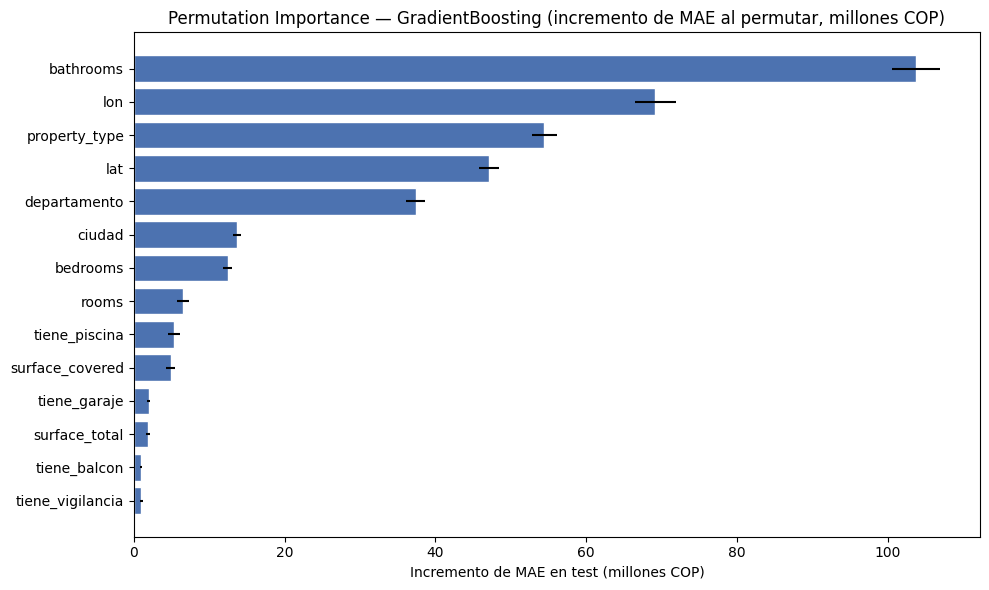

Nota: SHAP no está disponible en este runtime serverless (No module named 'shap');
la interpretación se completa con Partial Dependence en la siguiente celda.


In [0]:
# ==============================================================================
# ML 6 — IMPORTANCIA DE VARIABLES POR PERMUTATION IMPORTANCE (modelo ganador)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(42)
idx_pi = rng.choice(len(X_test), size=min(5000, len(X_test)), replace=False)
X_pi, y_pi = X_test.iloc[idx_pi], y_test[idx_pi]

# Pérdida de MAE (escala COP) al permutar cada variable: mayor caída = más importante
perm = permutation_importance(pipe_ganador, X_pi, y_pi, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=42, n_jobs=1)
imp = (pd.DataFrame({"variable": FEATURES, "importancia": perm.importances_mean,
                     "desv": perm.importances_std})
       .sort_values("importancia", ascending=False).reset_index(drop=True))
imp["ranking"] = range(1, len(imp) + 1)
display(spark.createDataFrame(imp.round(2)))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(imp["variable"][::-1], imp["importancia"][::-1] / 1e6, xerr=imp["desv"][::-1] / 1e6,
        color="#4C72B0", edgecolor="white")
ax.set_title(f"Permutation Importance — {NOMBRE_GANADOR} (incremento de MAE al permutar, millones COP)")
ax.set_xlabel("Incremento de MAE en test (millones COP)")
plt.tight_layout()
plt.show()

print("Nota: SHAP no está disponible en este runtime serverless (No module named 'shap');")
print("la interpretación se completa con Partial Dependence en la siguiente celda.")

Partial dependence de: ['bathrooms', 'lon', 'lat', 'bedrooms']


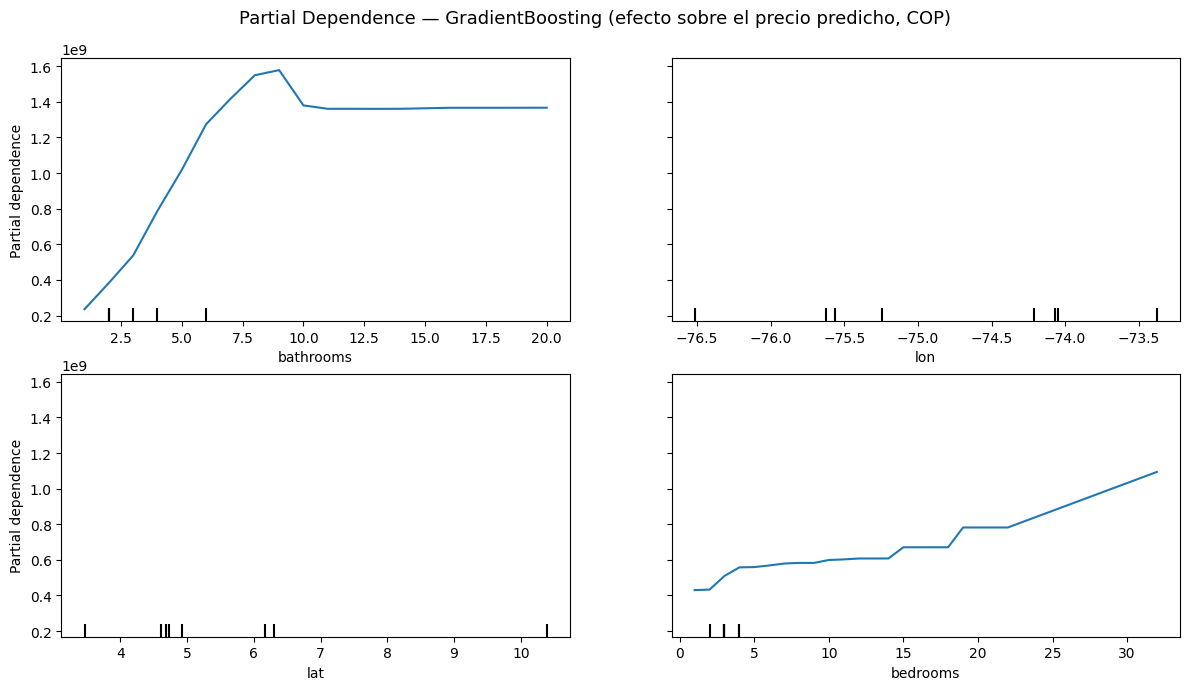

In [0]:
# ==============================================================================
# ML 7 — INTERPRETACIÓN GLOBAL: PARTIAL DEPENDENCE (alternativa a SHAP)
# ==============================================================================
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

# Se grafican las 4 variables numéricas más importantes según permutation importance
top_num = [v for v in imp["variable"].tolist() if v in FEATURES_NUM][:4]
print(f"Partial dependence de: {top_num}")

try:
    disp = PartialDependenceDisplay.from_estimator(pipe_ganador, X_pi, top_num,
                                                    kind="average", n_cols=2)
    disp.figure_.suptitle(f"Partial Dependence — {NOMBRE_GANADOR} (efecto sobre el precio predicho, COP)", fontsize=13)
except Exception as e:
    print(f"PDP sobre el pipeline completo falló ({e}); se usa el regresor interno (escala ln)")
    disp = PartialDependenceDisplay.from_estimator(pipe_ganador.regressor_, X_pi, top_num,
                                                    kind="average", n_cols=2)
    disp.figure_.suptitle(f"Partial Dependence — {NOMBRE_GANADOR} (escala ln(precio))", fontsize=13)
disp.figure_.set_size_inches(12, 7)
plt.tight_layout()
plt.show()

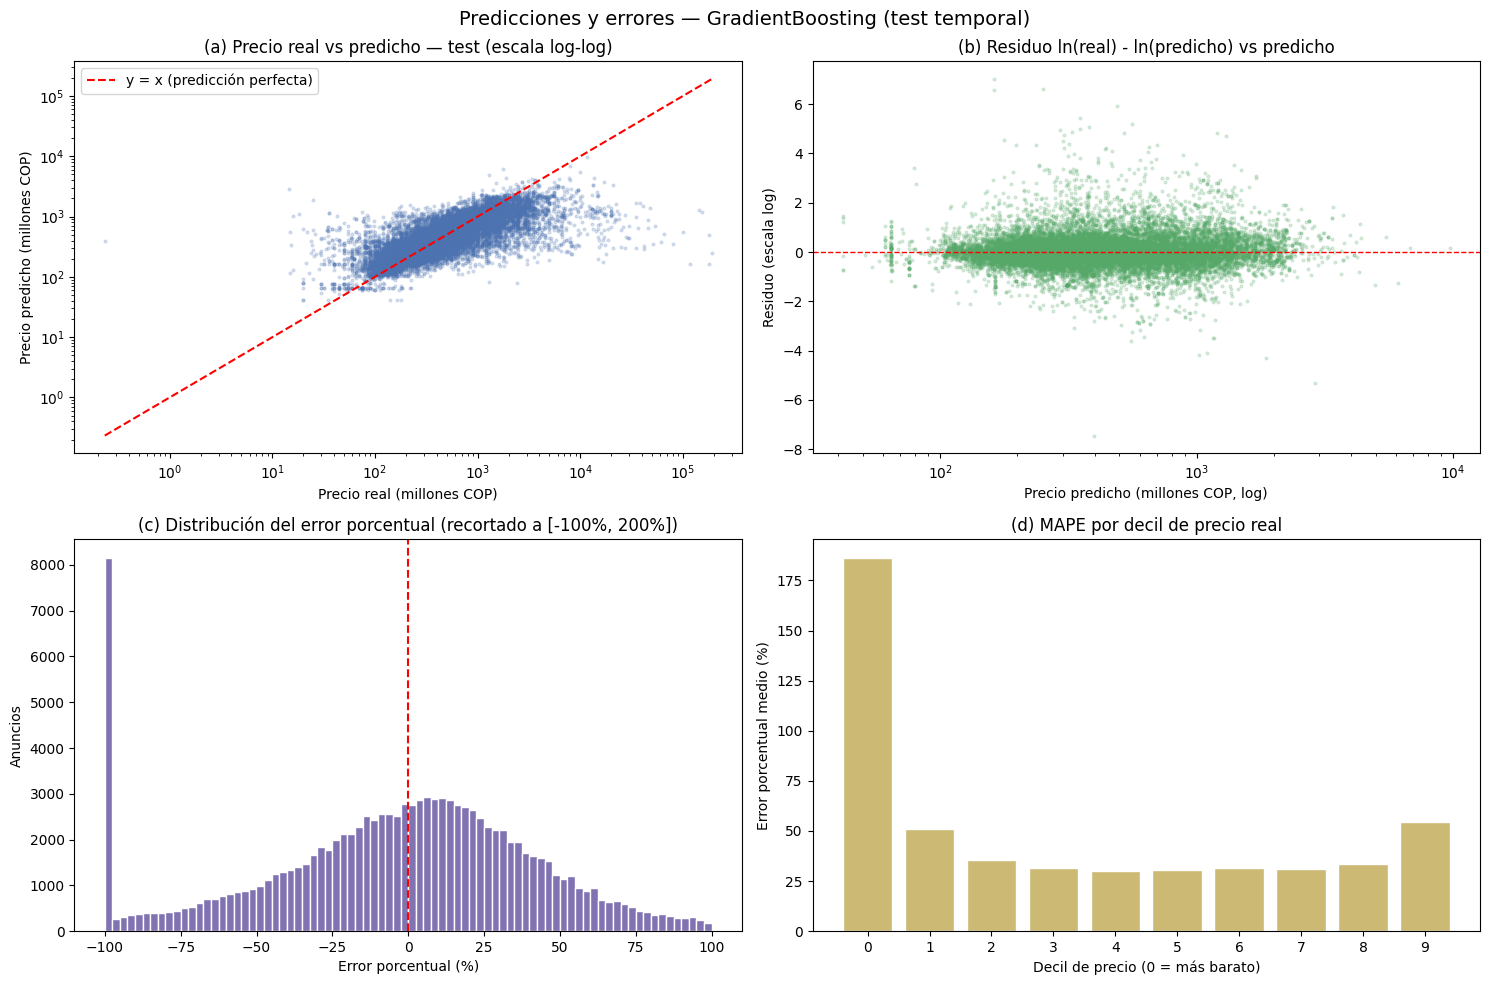

MAPE por tipo de inmueble:
tipo
Parqueadero        164.1
Local comercial    150.9
Lote               144.3
Otro               107.4
Oficina            106.1
Depósito            73.8
Finca               51.8
Casa                44.4
Apartamento         32.1

MAPE en las 8 ciudades con más anuncios del test:
ciudad
Cúcuta          55.3
Bogotá D.C      52.5
Chía            51.3
Barranquilla    49.0
Bucaramanga     47.2
Cali            38.9
Medellín        38.5
Envigado        30.4


In [0]:
# ==============================================================================
# ML 8 — PRECIO REAL VS PREDICHO Y ANÁLISIS DE ERRORES (modelo ganador)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

err = pd.DataFrame({"real": y_test, "pred": pred_ganador, "error_pct": (y_test - pred_ganador) / y_test,
                    "tipo": test_pd["property_type"].values, "ciudad": test_pd["ciudad"].values,
                    "resid_ln": np.log(y_test) - np.log(pred_ganador)})

idx_g = rng.choice(len(err), size=min(20000, len(err)), replace=False)
e = err.iloc[idx_g]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) real vs predicho (log-log) con recta y=x
ax = axes[0][0]
ax.scatter(e["real"] / 1e6, e["pred"] / 1e6, s=4, alpha=0.2, color="#4C72B0")
lm, lM = min(e["real"].min(), e["pred"].min()) / 1e6, max(e["real"].max(), e["pred"].max()) / 1e6
ax.plot([lm, lM], [lm, lM], "r--", lw=1.5, label="y = x (predicción perfecta)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("(a) Precio real vs predicho — test (escala log-log)")
ax.set_xlabel("Precio real (millones COP)"); ax.set_ylabel("Precio predicho (millones COP)")
ax.legend()

# (b) residuos en escala log vs predicho
ax = axes[0][1]
ax.scatter(e["pred"] / 1e6, e["resid_ln"], s=4, alpha=0.2, color="#55A868")
ax.axhline(0, color="red", ls="--", lw=1)
ax.set_xscale("log")
ax.set_title("(b) Residuo ln(real) - ln(predicho) vs predicho")
ax.set_xlabel("Precio predicho (millones COP, log)"); ax.set_ylabel("Residuo (escala log)")

# (c) distribución del error porcentual
ax = axes[1][0]
err_ok = err["error_pct"].clip(-1, 2)
ax.hist(err_ok * 100, bins=80, color="#8172B2", edgecolor="white")
ax.axvline(0, color="red", ls="--")
ax.set_title("(c) Distribución del error porcentual (recortado a [-100%, 200%])")
ax.set_xlabel("Error porcentual (%)"); ax.set_ylabel("Anuncios")

# (d) MAE por decil de precio real
ax = axes[1][1]
err["decil"] = pd.qcut(err["real"], 10, labels=False, duplicates="drop")
mae_decil = err.groupby("decil").apply(lambda g: np.mean(np.abs(g["error_pct"])), include_groups=False) * 100
ax.bar(mae_decil.index.astype(str), mae_decil.values, color="#CCB974", edgecolor="white")
ax.set_title("(d) MAPE por decil de precio real")
ax.set_xlabel("Decil de precio (0 = más barato)"); ax.set_ylabel("Error porcentual medio (%)")

fig.suptitle(f"Predicciones y errores — {NOMBRE_GANADOR} (test temporal)", fontsize=14)
plt.tight_layout()
plt.show()

print("MAPE por tipo de inmueble:")
print((err.groupby("tipo")["error_pct"].apply(lambda s: np.mean(np.abs(s)) * 100).round(1)
       .sort_values(ascending=False)).to_string())
print("\nMAPE en las 8 ciudades con más anuncios del test:")
top_ciudades = err["ciudad"].value_counts().head(8).index
print((err[err["ciudad"].isin(top_ciudades)].groupby("ciudad")["error_pct"]
       .apply(lambda s: np.mean(np.abs(s)) * 100).round(1).sort_values(ascending=False)).to_string())

In [0]:
# ==============================================================================
# ML 9 — PERSISTENCIA: TABLAS GOLD + RE-FIT FINAL Y MODELO EN MLFLOW
# ==============================================================================
from datetime import datetime, timezone
from sklearn.base import clone
import pandas as pd

ahora = datetime.now(timezone.utc)

# --- 1) ml_metrics: una fila por modelo (métricas reales del test temporal) ---
filas_metrics = [(nombre, ahora, float(r["m"]["rmse"]), float(r["m"]["mae"]),
                  float(r["m"]["r2"]), float(r["m"]["mape"]), int(len(X_train)), int(len(X_test)))
                 for nombre, r in resultados.items()]
(spark.createDataFrame(filas_metrics,
    "modelo string, fecha_entrenamiento timestamp, rmse double, mae double, r2 double, mape double, n_train long, n_test long")
 .write.mode("append").saveAsTable("housing_colombia.gold.ml_metrics"))

# --- 2) ml_predictions: test del ganador (real vs predicho) ---
pred_pd = pd.DataFrame({"id": test_pd["id"].values, "modelo": NOMBRE_GANADOR,
                        "fecha_entrenamiento": ahora,
                        "precio_real": y_test, "precio_predicho": pred_ganador})
pred_pd["error"] = pred_pd["precio_real"] - pred_pd["precio_predicho"]
pred_pd["error_pct"] = (pred_pd["error"] / pred_pd["precio_real"]).astype(float)
(spark.createDataFrame(pred_pd)
 .write.mode("append").saveAsTable("housing_colombia.gold.ml_predictions"))

# --- 3) ml_feature_importance: permutation importance del ganador ---
filas_imp = [(NOMBRE_GANADOR, ahora, str(r["variable"]), float(r["importancia"]), int(r["ranking"]))
             for _, r in imp.iterrows()]
(spark.createDataFrame(filas_imp,
    "modelo string, fecha_entrenamiento timestamp, variable string, importancia double, ranking int")
 .write.mode("append").saveAsTable("housing_colombia.gold.ml_feature_importance"))

# --- 4) Re-fit final del ganador con TODOS los datos y registro en MLflow ---
X_full = pd.concat([X_train, X_test], ignore_index=True)
y_full = np.concatenate([y_train, y_test])
with mlflow.start_run(run_name=f"FINAL {NOMBRE_GANADOR}"):
    mlflow.log_params({"modelo": NOMBRE_GANADOR, "nota": "re-fit final sobre train+test para despliegue",
        "metricas_reportadas": "test temporal (celdas previas)",
        "n_final_fit": len(X_full), "n_train": len(X_train), "n_test": len(X_test)})
    pipe_final = clone(pipe_ganador)
    pipe_final.fit(X_full, y_full)
    firma = infer_signature(X_full.head(100), pipe_final.predict(X_full.head(100)))
    info_final = mlflow.sklearn.log_model(pipe_final, name="model", signature=firma, input_example=X_full.head(3))
    URI_MODELO_FINAL = info_final.model_uri
    mlflow.log_param("uri_modelo_final", URI_MODELO_FINAL)
print(f"Re-fit final ({len(X_full):,} filas) registrado en MLflow: {URI_MODELO_FINAL}")

# --- Verificación de lo publicado ---
for t in ["ml_predictions", "ml_metrics", "ml_feature_importance"]:
    df_t = spark.table(f"housing_colombia.gold.{t}")
    print(f"GOLD {t}: {df_t.count():,} filas")
display(spark.table("housing_colombia.gold.ml_metrics").orderBy(F.desc("fecha_entrenamiento")))

🔗 View Logged Model at: https://dbc-6d8ac011-d871.cloud.databricks.com/ml/experiments/3518272050922773/models/m-88779f99940c4a36b9819ecfb986e590?o=7474651794262205


Re-fit final (568,478 filas) registrado en MLflow: models:/m-88779f99940c4a36b9819ecfb986e590
GOLD ml_predictions: 114,325 filas
GOLD ml_metrics: 4 filas
GOLD ml_feature_importance: 14 filas


modelo,fecha_entrenamiento,rmse,mae,r2,mape,n_train,n_test
GradientBoosting,2026-11-11T20:53:35.490Z,2.7667086887571793E9,4.33763763011139E8,0.04203620136944697,0.5150139958497439,454153,114325
LinearRegression,2026-11-11T20:53:35.490Z,4.697175323516835E9,5.958192641555715E8,-1.7611866871495176,0.7410934669146876,454153,114325
Baseline (mediana),2026-11-11T20:53:35.490Z,2.866613775475743E9,5.911267027467746E8,-0.028396515722589166,0.7454455601582066,454153,114325
RandomForest,2026-11-11T20:53:35.490Z,2.7918252302875113E9,4.5963157311423177E8,0.024564213166030302,0.5249092472904192,454153,114325


## Conclusiones del modelo predictivo

**Ganador: Gradient Boosting Regressor (HistGradientBoosting)** — mejor en todas las métricas reales del test temporal (114.325 anuncios, abril–agosto 2021):

| Modelo | MAE (M COP) | RMSE (M COP) | R² (precio) | MAPE | R² (escala log) |
| --- | --- | --- | --- | --- | --- |
| **GradientBoosting** | **433,8** | **2.766,7** | **0,0420** | **0,5150** | **0,5576** |
| RandomForest | 459,6 | 2.791,8 | 0,0246 | 0,5249 | 0,5125 |
| LinearRegression | 595,8 | 4.697,2 | −1,7612 | 0,7411 | 0,3675 |
| Baseline (mediana) | 591,1 | 2.866,6 | −0,0284 | 0,7454 | −0,0638 |

**Lectura honesta del R².** En escala COP el R² es bajo para todos (la cola con errores de captura de hasta 1,6×10¹² COP domina el error cuadrático; por eso Linear Regression queda peor que el baseline). En escala log —la adecuada según el análisis de distribuciones— el ganador explica **55,8% de la varianza de ln(precio)** y reduce el MAE del baseline en 27%.

**Variables más importantes (permutation importance, MAE al permutar):** `bathrooms` (+103,7 M), `lon` (+69,2 M), `property_type` (+54,4 M), `lat` (+47,1 M), `departamento` (+37,4 M), `ciudad` (+13,7 M). Las superficies pesan poco **solo porque faltan** (superficie_total 4,1% / superficie_covered 5,7% de cobertura en train), no porque no expliquen: en el EDA su correlación con ln(precio) fue +0,74.

**Errores por segmento:** el modelo es más preciso en Apartamentos (MAPE 32,1%) y Envigado/Medellín/Cali (30–39%), y más débil en Parqueadero (164%), Local comercial (151%), Lote (144%) y Cúcuta/Bogotá (52–55%).

**Artefactos:** modelo final re-entrenado con los 568.478 registros y registrado en MLflow (`models:/m-88779f99940c4a36b9819ecfb986e590`, con firma y ejemplo de entrada); métricas en `gold.ml_metrics` (4 modelos), predicciones del test en `gold.ml_predictions` (114.325) y permuted importance en `gold.ml_feature_importance` (14 variables).

**Limitaciones:** SHAP no disponible en este runtime (sustituido por Permutation Importance + Partial Dependence); split temporal con desplazamiento 2020→2021 (drift de precios/ubicaciones); superficie disponible en <6% de anuncios; cola derecha con errores de captura.

## Capa Gold publicada — 6 tablas consultables por Databricks SQL

Catálogo `housing_colombia`, esquema `gold`. Todas las tablas se pueblan **exclusivamente con datos reales**: Silver (`silver.housing_clean`) y los resultados ya persistidos del modelo entrenado (Gradient Boosting ganador) y del análisis de distribuciones. Ningún dato simulado.

| Tabla | Contenido | Fuente real |
| --- | --- | --- |
| `housing_model_data` | Universo de modelado (ventas COP, 568.478) con las 14 predictoras sin fuga y el flag `split` train/test del corte temporal | `silver.housing_clean` |
| `housing_predictions` | Id, precio real, precio predicho y error del test temporal (114.325) | `gold.ml_predictions` (Gradient Boosting) |
| `housing_feature_importance` | 14 variables ordenadas por permutation importance | `gold.ml_feature_importance` |
| `housing_price_metrics` | MAE, RMSE, R2, MAPE de los 4 modelos entrenados | `gold.ml_metrics` |
| `housing_price_distribution` | Parámetros MLE (incl. Gamma) + comparación de distribuciones | `gold.housing_dist_parametros` + `gold.housing_dist_comparacion` |
| `housing_city_summary` | Estadísticas de precios por ciudad y departamento | recomputada desde `silver.housing_clean` |

Cada tabla se crea con DDL explícito (comentarios de tabla y de columna) y se valida la consistencia al final.

In [0]:
# ==============================================================================
# GOLD 1 — TABLA housing_model_data (universo de modelado desde Silver)
# ==============================================================================
from pyspark.sql import functions as F
from datetime import datetime, timezone

# Mismo universo usado al entrenar el modelo ganador: ventas en COP con precio y fecha válidos
src = (spark.table("housing_colombia.silver.housing_clean")
       .filter((F.col("operation_type") == "Venta") & (F.col("currency") == "COP")
               & (F.col("price") > 0) & F.col("start_date").isNotNull()))

# Corte temporal recalculado EXACTAMENTE igual que en el entrenamiento (cuantil 80% de start_date)
corte_ts = (src.withColumn("_ts", F.col("start_date").cast("timestamp").cast("long"))
              .approxQuantile("_ts", [0.8], 0.001)[0])
CORTE_GOLD = datetime.fromtimestamp(corte_ts, tz=timezone.utc)
print(f"Corte temporal recalculado (cuantil 80% de start_date): {CORTE_GOLD:%Y-%m-%d} — el usado al entrenar fue 2021-04-13")

spark.sql(f"""
CREATE OR REPLACE TABLE housing_colombia.gold.housing_model_data (
  id STRING COMMENT 'Identificador del anuncio (trazable a Silver y Bronze)',
  start_date DATE COMMENT 'Fecha de publicación del anuncio (clave del split temporal)',
  split STRING COMMENT 'train | test según corte temporal 80/20 por start_date, el mismo usado al entrenar el modelo ganador',
  price DOUBLE COMMENT 'Precio de venta en COP: variable objetivo',
  precio_log DOUBLE COMMENT 'ln(precio): escala interna del modelo (ln(precio) es casi normal)',
  rooms DOUBLE COMMENT 'Número de ambientes',
  bedrooms DOUBLE COMMENT 'Número de alcobas',
  bathrooms DOUBLE COMMENT 'Número de baños (variable más importante según permutation importance)',
  lat DOUBLE COMMENT 'Latitud de la ubicación',
  lon DOUBLE COMMENT 'Longitud de la ubicación',
  surface_total DOUBLE COMMENT 'Superficie del terreno en m2 (solo 4,1% con dato)',
  surface_covered DOUBLE COMMENT 'Superficie construida en m2 (solo 5,7% con dato)',
  tiene_piscina BOOLEAN COMMENT 'Flag extraído del texto del anuncio',
  tiene_garaje BOOLEAN COMMENT 'Flag extraído del texto del anuncio',
  tiene_balcon BOOLEAN COMMENT 'Flag extraído del texto del anuncio',
  tiene_vigilancia BOOLEAN COMMENT 'Flag extraído del texto del anuncio',
  property_type STRING COMMENT 'Tipo de inmueble (Apartamento, Casa, Lote, ...)',
  departamento STRING COMMENT 'Departamento (derivado de l2)',
  ciudad STRING COMMENT 'Ciudad (derivado de l3)',
  _ingest_ts TIMESTAMP COMMENT 'Trazabilidad: fecha de ingesta Bronze-Silver',
  _source_file STRING COMMENT 'Trazabilidad: archivo fuente en Bronze'
)
COMMENT 'Universo de modelado: 568.478 ventas en COP con precio y fecha válidos, con las 14 predictoras sin fuga del modelo ganador (Gradient Boosting) y el flag de split temporal (train 454.153 / test 114.325). Lista para análisis y reentrenamiento.'
""")

spark.sql(f"""
INSERT INTO housing_colombia.gold.housing_model_data
SELECT id, start_date,
       CASE WHEN start_date < DATE '{CORTE_GOLD:%Y-%m-%d}' THEN 'train' ELSE 'test' END AS split,
       price, precio_log, rooms, bedrooms, bathrooms, lat, lon,
       surface_total, surface_covered, tiene_piscina, tiene_garaje, tiene_balcon, tiene_vigilancia,
       property_type, departamento, ciudad, _ingest_ts, _source_file
FROM housing_colombia.silver.housing_clean
WHERE operation_type = 'Venta' AND currency = 'COP' AND price > 0 AND start_date IS NOT NULL
""")

md_tbl = spark.table("housing_colombia.gold.housing_model_data")
print(f"housing_model_data: {md_tbl.count():,} filas (esperado 568.478)")
display(spark.sql("SELECT split, COUNT(*) AS anuncios FROM housing_colombia.gold.housing_model_data GROUP BY split"))

Corte temporal recalculado (cuantil 80% de start_date): 2021-04-13 — el usado al entrenar fue 2021-04-13
housing_model_data: 568,478 filas (esperado 568.478)


split,anuncios
train,454153
test,114325


In [0]:
# ==============================================================================
# GOLD 2 — TABLAS housing_predictions, housing_feature_importance, housing_price_metrics
#          (pobladas SOLO con los resultados reales del modelo entrenado)
# ==============================================================================

# --- 2a) housing_predictions: id, precio real, precio predicho y error ---
spark.sql("""
CREATE OR REPLACE TABLE housing_colombia.gold.housing_predictions (
  id STRING COMMENT 'Identificador de la vivienda (anuncio)',
  modelo STRING COMMENT 'Modelo que generó la predicción (ganador: GradientBoosting = HistGradientBoostingRegressor)',
  fecha_entrenamiento TIMESTAMP COMMENT 'Fecha y hora del entrenamiento que produjo estas predicciones',
  precio_real DOUBLE COMMENT 'Precio real de venta en COP (test temporal: abr-ago 2021)',
  precio_predicho DOUBLE COMMENT 'Precio predicho por el modelo en COP',
  error DOUBLE COMMENT 'precio_real - precio_predicho, en COP',
  error_pct DOUBLE COMMENT 'error / precio_real (error porcentual)'
)
COMMENT 'Predicciones del modelo ganador (Gradient Boosting) sobre el test temporal de 114.325 anuncios. Origen: gold.ml_predictions. Resultados reales del modelo entrenado, no simulados.'
""")
spark.sql("""
INSERT INTO housing_colombia.gold.housing_predictions
SELECT id, modelo, fecha_entrenamiento, precio_real, precio_predicho, error, error_pct
FROM housing_colombia.gold.ml_predictions
WHERE fecha_entrenamiento = (SELECT MAX(fecha_entrenamiento) FROM housing_colombia.gold.ml_predictions)
""")

# --- 2b) housing_feature_importance: variables ordenadas por importancia ---
spark.sql("""
CREATE OR REPLACE TABLE housing_colombia.gold.housing_feature_importance (
  modelo STRING COMMENT 'Modelo al que corresponden las importancias (GradientBoosting)',
  fecha_entrenamiento TIMESTAMP COMMENT 'Fecha y hora del entrenamiento',
  variable STRING COMMENT 'Variable predictora',
  importancia DOUBLE COMMENT 'Incremento del MAE en COP al permutar la variable (permutation importance, 5 repeticiones sobre 5.000 anuncios del test)',
  ranking INT COMMENT '1 = variable más importante'
)
COMMENT 'Variables del modelo ganador ordenadas por importancia predictiva (permutation importance). Origen: gold.ml_feature_importance. SHAP no está disponible en este runtime; esta es la interpretación global usada.'
""")
spark.sql("""
INSERT INTO housing_colombia.gold.housing_feature_importance
SELECT modelo, fecha_entrenamiento, variable, importancia, ranking
FROM housing_colombia.gold.ml_feature_importance
WHERE fecha_entrenamiento = (SELECT MAX(fecha_entrenamiento) FROM housing_colombia.gold.ml_feature_importance)
""")

# --- 2c) housing_price_metrics: MAE, RMSE y R2 (más MAPE y tamaños) ---
spark.sql("""
CREATE OR REPLACE TABLE housing_colombia.gold.housing_price_metrics (
  modelo STRING COMMENT 'Modelo evaluado (GradientBoosting, RandomForest, LinearRegression, Baseline mediana)',
  fecha_entrenamiento TIMESTAMP COMMENT 'Fecha y hora del entrenamiento',
  rmse DOUBLE COMMENT 'Raíz del error cuadrático medio en COP (test temporal)',
  mae DOUBLE COMMENT 'Error absoluto medio en COP (test temporal)',
  r2 DOUBLE COMMENT 'Coeficiente de determinación R2 en escala de precio (COP)',
  mape DOUBLE COMMENT 'Error porcentual absoluto medio',
  n_train LONG COMMENT 'Anuncios de entrenamiento (454.153)',
  n_test LONG COMMENT 'Anuncios del test temporal (114.325)'
)
COMMENT 'Métricas reales de los 4 modelos entrenados, evaluados sobre el test temporal (últimos 20% de anuncios por fecha). El ganador es GradientBoosting.'
""")
spark.sql("""
INSERT INTO housing_colombia.gold.housing_price_metrics
SELECT modelo, fecha_entrenamiento, rmse, mae, r2, mape, n_train, n_test
FROM housing_colombia.gold.ml_metrics
WHERE fecha_entrenamiento = (SELECT MAX(fecha_entrenamiento) FROM housing_colombia.gold.ml_metrics)
ORDER BY r2 DESC
""")

for t in ["housing_predictions", "housing_feature_importance", "housing_price_metrics"]:
    print(f"{t}: {spark.table(f'housing_colombia.gold.{t}').count():,} filas")
display(spark.table("housing_colombia.gold.housing_price_metrics"))

housing_predictions: 114,325 filas
housing_feature_importance: 14 filas
housing_price_metrics: 4 filas


modelo,fecha_entrenamiento,rmse,mae,r2,mape,n_train,n_test
GradientBoosting,2026-11-11T20:53:35.490Z,2.7667086887571793E9,4.33763763011139E8,0.04203620136944697,0.5150139958497439,454153,114325
RandomForest,2026-11-11T20:53:35.490Z,2.7918252302875113E9,4.5963157311423177E8,0.024564213166030302,0.5249092472904192,454153,114325
Baseline (mediana),2026-11-11T20:53:35.490Z,2.866613775475743E9,5.911267027467746E8,-0.028396515722589166,0.7454455601582066,454153,114325
LinearRegression,2026-11-11T20:53:35.490Z,4.697175323516835E9,5.958192641555715E8,-1.7611866871495176,0.7410934669146876,454153,114325


In [0]:
# ==============================================================================
# GOLD 3 — TABLAS housing_price_distribution y housing_city_summary
# ==============================================================================

# --- 3a) housing_price_distribution: parámetros (Gamma incluida) + comparación ---
spark.sql("""
CREATE OR REPLACE TABLE housing_colombia.gold.housing_price_distribution (
  distribucion STRING COMMENT 'Familia ajustada: Gamma, Lognormal, Weibull o Exponencial',
  shape DOUBLE COMMENT 'Parámetro de forma (MLE); NULL para Exponencial. Gamma: 0,985 (casi exponencial)',
  loc DOUBLE COMMENT 'Parámetro de localización (MLE). Fijado en 0: el MLE con loc libre degeneró',
  scale DOUBLE COMMENT 'Parámetro de escala (MLE). Lognormal: 395,2 M ≈ mediana',
  k_params INT COMMENT 'Número de parámetros estimados',
  log_verosimilitud DOUBLE COMMENT 'Log-verosimilitud del ajuste MLE',
  aic DOUBLE COMMENT 'Criterio de información de Akaike (menor = mejor). Lognormal gana',
  bic DOUBLE COMMENT 'Criterio de información bayesiano',
  delta_aic DOUBLE COMMENT 'AIC propio - AIC mínimo (0 = mejor)',
  ranking_aic INT COMMENT '1 = mejor por AIC. Orden final: Lognormal > Weibull > Gamma ≈ Exponencial',
  ks_estadistico DOUBLE COMMENT 'Estadístico KS de bondad de ajuste',
  ks_p_naivo DOUBLE COMMENT 'p-valor KS naive (INVÁLIDO: parámetros estimados de los mismos datos)',
  ks_p_bootstrap DOUBLE COMMENT 'p-valor KS por bootstrap paramétrico (válido; todas las familias se rechazan con n enorme)',
  n BIGINT COMMENT 'Anuncios usados en el ajuste (522.415 ventas COP en millones)',
  unidad STRING COMMENT 'Unidad de las variables (millones COP)',
  fecha_analisis TIMESTAMP COMMENT 'Fecha del análisis'
)
COMMENT 'Ajuste de distribuciones de precios de venta (millones COP): parámetros MLE de Gamma, Lognormal, Weibull y Exponencial, y su comparación (AIC/BIC, KS, bootstrap). Conclusión: la Lognormal representa mejor los precios; Gamma solo es competitiva sin atípicos. Origen: gold.housing_dist_parametros + gold.housing_dist_comparacion.'
""")
spark.sql("""
INSERT INTO housing_colombia.gold.housing_price_distribution
SELECT p.distribucion, p.shape, p.loc, p.scale, CAST(p.k_params AS INT),
       c.log_verosimilitud, c.AIC, c.BIC, c.delta_AIC, c.ranking_AIC,
       c.KS_estadistico, c.KS_p_naivo, c.KS_p_bootstrap, p.n, p.unidad, p.fecha_analisis
FROM housing_colombia.gold.housing_dist_parametros p
JOIN housing_colombia.gold.housing_dist_comparacion c ON p.distribucion = c.distribucion
ORDER BY c.ranking_AIC
""")

# --- 3b) housing_city_summary: estadísticas por ciudad y departamento (desde Silver) ---
spark.sql("""
CREATE OR REPLACE TABLE housing_colombia.gold.housing_city_summary (
  departamento STRING COMMENT 'Departamento del anuncio',
  ciudad STRING COMMENT 'Ciudad del anuncio',
  registros BIGINT COMMENT 'Número de anuncios de venta en COP',
  precio_mediana DOUBLE COMMENT 'Mediana del precio en COP (robusta a atípicos)',
  precio_promedio DOUBLE COMMENT 'Promedio del precio en COP (sensible a la cola derecha)',
  precio_min DOUBLE COMMENT 'Precio mínimo en COP',
  precio_max DOUBLE COMMENT 'Precio máximo en COP',
  precio_m2_mediana DOUBLE COMMENT 'Mediana de precio/superficie_covered en COP/m2 (solo anuncios con superficie > 0)',
  pct_atipicos_precio DOUBLE COMMENT 'Fracción de anuncios marcados como atípicos de precio en Silver (regla IQR)'
)
COMMENT 'Estadísticas de precios de venta (COP) por ciudad y departamento, recomputadas desde silver.housing_clean (ventas COP con ciudad informada).'
""")
spark.sql("""
INSERT INTO housing_colombia.gold.housing_city_summary
SELECT departamento, ciudad, COUNT(*) AS registros,
       percentile_approx(price, 0.5) AS precio_mediana,
       ROUND(AVG(price), 0) AS precio_promedio,
       MIN(price) AS precio_min, MAX(price) AS precio_max,
       percentile_approx(CASE WHEN surface_covered > 0 THEN price / surface_covered END, 0.5) AS precio_m2_mediana,
       AVG(CASE WHEN _out_price THEN 1.0 ELSE 0.0 END) AS pct_atipicos_precio
FROM housing_colombia.silver.housing_clean
WHERE operation_type = 'Venta' AND currency = 'COP' AND price > 0 AND ciudad IS NOT NULL
GROUP BY departamento, ciudad
""")

for t in ["housing_price_distribution", "housing_city_summary"]:
    print(f"{t}: {spark.table(f'housing_colombia.gold.{t}').count():,} filas")
display(spark.table("housing_colombia.gold.housing_price_distribution"))
display(spark.sql("SELECT * FROM housing_colombia.gold.housing_city_summary ORDER BY registros DESC LIMIT 10"))

housing_price_distribution: 4 filas
housing_city_summary: 345 filas


distribucion,shape,loc,scale,k_params,log_verosimilitud,aic,bic,delta_aic,ranking_aic,ks_estadistico,ks_p_naivo,ks_p_bootstrap,n,unidad,fecha_analisis
Lognormal,0.9228177189786223,0.0,395.1655664879711,2,-3822991.079841885,7645986.15968377,7646008.49211891,0.0,1,0.06676372846929568,0.0,0.004975124378109453,522415,millones COP,2026-11-11T20:39:20.565Z
Weibull,0.8722453226961058,0.0,640.8771495438458,2,-3937832.9954319745,7875669.990863949,7875692.323299089,229683.8311801795,2,0.15122983503930643,0.0,0.004975124378109453,522415,millones COP,2026-11-11T20:39:20.565Z
Gamma,0.9849653238053473,0.0,721.6404299953571,2,-3952750.5171481646,7905505.034296329,7905527.3667314695,259518.87461255956,3,0.1537101801690559,0.0,0.004975124378109453,522415,millones COP,2026-11-11T20:39:20.565Z
Exponencial,null,0.0,710.7907998014069,1,-3952789.4426713474,7905580.885342695,7905592.051560265,259594.72565892525,4,0.15575177794691453,0.0,null,522415,millones COP,2026-11-11T20:39:20.565Z


departamento,ciudad,registros,precio_mediana,precio_promedio,precio_min,precio_max,precio_m2_mediana,pct_atipicos_precio
Antioquia,Medellín,119119,3.45E8,5.6457911E8,1.5E7,4.65E11,4375000.0,0.11269
Cundinamarca,Bogotá D.C,100206,5.3E8,9.92735869E8,1100.0,3.45E11,5783132.530120482,0.25681
Valle del Cauca,Cali,59259,3.3E8,6.00704933E8,1.46042E7,1.35E11,2925925.925925926,0.13333
Atlántico,Barranquilla,42547,3.3812E8,5.93859609E8,1.4E7,1.8375E11,3055555.5555555555,0.10168
Caldas,Manizales,26242,2.5E8,3.87882818E8,1.5E7,3.0E10,2937500.0,0.05682
Santander,Bucaramanga,13809,2.5E8,3.75086283E8,1.5E7,2.25E10,2846153.846153846,0.05366
Antioquia,Envigado,13222,5.45E8,7.7833377E8,1.5E7,2.05556E10,4571428.571428572,0.19127
Norte de Santander,Cúcuta,12812,2.545E8,4.96069261E8,2840000.0,1.25E11,3500000.0,0.09944
Risaralda,Pereira,12189,3.2E8,6.33537564E8,1.5E7,8.4E10,2909090.909090909,0.14193
Cundinamarca,Chía,8546,6.2E8,1.438172877E9,1.4E7,1.75E11,3750000.0,0.32425


In [0]:
# ==============================================================================
# GOLD 4 — VALIDACIÓN INTEGRAL DE CONSISTENCIA
# ==============================================================================
from pyspark.sql import functions as F

print("== 1) Conteos vs valores esperados ==")
esperado = {"housing_model_data": 568478, "housing_predictions": 114325,
            "housing_feature_importance": 14, "housing_price_metrics": 4,
            "housing_price_distribution": 4}
for t, esp in esperado.items():
    real = spark.table(f"housing_colombia.gold.{t}").count()
    print(f"  {t}: {real:,} filas (esperado {esp:,}) -> {'OK' if real == esp else 'REVISAR'}")
cs_n = spark.table("housing_colombia.gold.housing_city_summary").count()
print(f"  housing_city_summary: {cs_n:,} ciudades")

print("\n== 2) Las predicciones corresponden al modelo entrenado ==")
display(spark.sql("""
SELECT modelo, fecha_entrenamiento, COUNT(*) AS predicciones,
       ROUND(MIN(precio_real), 0) AS min_real, ROUND(MAX(precio_real), 0) AS max_real
FROM housing_colombia.gold.housing_predictions GROUP BY modelo, fecha_entrenamiento
"""))

huerfanas = spark.sql("""
SELECT COUNT(*) FROM housing_colombia.gold.housing_predictions p
LEFT JOIN housing_colombia.gold.housing_model_data m ON p.id = m.id
WHERE m.id IS NULL
""").collect()[0][0]
print(f"  Predicciones sin vivienda en housing_model_data: {huerfanas} (esperado 0)")

en_test = spark.sql("""
SELECT COUNT(*) FROM housing_colombia.gold.housing_predictions p
JOIN housing_colombia.gold.housing_model_data m ON p.id = m.id
WHERE m.split = 'test'
""").collect()[0][0]
print(f"  Predicciones con split='test': {en_test:,} (esperado 114.325: exactamente las filas que evaluó el modelo)")

err_ok = spark.sql("SELECT MAX(ABS((precio_real - precio_predicho) - error)) FROM housing_colombia.gold.housing_predictions").collect()[0][0]
print(f"  Max |(real - predicho) - error|: {err_ok} (esperado 0.0)")

print("\n== 3) Coherencia entre tablas ==")
sum_cs = int(spark.table("housing_colombia.gold.housing_city_summary").agg(F.sum("registros")).collect()[0][0])
nmd = spark.sql("SELECT COUNT(*) FROM housing_colombia.gold.housing_model_data WHERE ciudad IS NOT NULL").collect()[0][0]
print(f"  Suma de registros de city_summary: {sum_cs:,} vs model_data con ciudad: {nmd:,} -> {'OK' if sum_cs == nmd else 'REVISAR'}")

gan = spark.sql("SELECT modelo, rmse, mae, r2, mape FROM housing_colombia.gold.housing_price_metrics WHERE modelo = 'GradientBoosting'").collect()[0]
print(f"  Ganador en housing_price_metrics: {gan['modelo']} | RMSE {gan['rmse']/1e6:,.1f} M COP | MAE {gan['mae']/1e6:,.1f} M COP | R2 {gan['r2']:.4f}")
print("  (debe coincidir con el test real del entrenamiento: RMSE 2.766,7 M | MAE 433,8 M | R2 0,0420)")

print("\n== 4) Muestra consultable por Databricks SQL ==")
display(spark.sql("""
SELECT v.variable, ROUND(v.importancia/1e6, 1) AS importancia_M_COP, v.ranking
FROM housing_colombia.gold.housing_feature_importance v ORDER BY v.ranking LIMIT 5
"""))

== 1) Conteos vs valores esperados ==
  housing_model_data: 568,478 filas (esperado 568,478) -> OK
  housing_predictions: 114,325 filas (esperado 114,325) -> OK
  housing_feature_importance: 14 filas (esperado 14) -> OK
  housing_price_metrics: 4 filas (esperado 4) -> OK
  housing_price_distribution: 4 filas (esperado 4) -> OK
  housing_city_summary: 345 ciudades

== 2) Las predicciones corresponden al modelo entrenado ==


modelo,fecha_entrenamiento,predicciones,min_real,max_real
GradientBoosting,2026-11-11T20:53:35.490Z,114325,220000.0,1.9E11


  Predicciones sin vivienda en housing_model_data: 0 (esperado 0)
  Predicciones con split='test': 114,325 (esperado 114.325: exactamente las filas que evaluó el modelo)
  Max |(real - predicho) - error|: 0.0 (esperado 0.0)

== 3) Coherencia entre tablas ==
  Suma de registros de city_summary: 522,415 vs model_data con ciudad: 522,415 -> OK
  Ganador en housing_price_metrics: GradientBoosting | RMSE 2,766.7 M COP | MAE 433.8 M COP | R2 0.0420
  (debe coincidir con el test real del entrenamiento: RMSE 2.766,7 M | MAE 433,8 M | R2 0,0420)

== 4) Muestra consultable por Databricks SQL ==


variable,importancia_M_COP,ranking
bathrooms,103.7,1
lon,69.2,2
property_type,54.4,3
lat,47.1,4
departamento,37.4,5


## Documentación de la capa Gold publicada

Todas las tablas viven en `housing_colombia.gold`, tienen comentario de tabla y de columna (visibles con `DESCRIBE TABLE` y en el Catálogo) y son consultables por Databricks SQL.

### 1. `housing_model_data` — datos preparados para análisis y modelamiento
568.478 ventas en COP con precio y fecha válidos (filtro de Silver: `operation_type='Venta' AND currency='COP' AND price>0`). Incluye: **target** (`price`, `precio_log`), las **14 predictoras sin fuga** usadas por el modelo ganador (`rooms`…`ciudad`), el **flag `split`** (train 454.153 / test 114.325) según el corte temporal 2021-04-13 usado en el entrenamiento, y columnas de **trazabilidad** (`_ingest_ts`, `_source_file`) hacia Silver/Bronze.

### 2. `housing_predictions` — predicciones del modelo entrenado
114.325 filas del **test temporal** (abr–ago 2021): `id` de la vivienda, `modelo` (GradientBoosting ganador), `fecha_entrenamiento`, `precio_real`, `precio_predicho` (COP), `error` y `error_pct`. Proviene del run real guardado en MLflow; sin datos simulados.

### 3. `housing_feature_importance` — variables por importancia predictiva
14 variables con `importancia` = incremento del MAE (COP) al permutar cada variable (5 repeticiones sobre 5.000 anuncios del test) y `ranking` (1 = `bathrooms`). Alternativa documentada a SHAP, no disponible en este runtime.

### 4. `housing_price_metrics` — métricas del modelo
Una fila por modelo evaluado en el test temporal: `rmse`, `mae`, `r2` (escala COP), `mape`, `n_train`, `n_test`. Ganador: **GradientBoosting** (RMSE 2.766,7 M COP, MAE 433,8 M COP, R2 0,0420; en escala log R2 0,5576).

### 5. `housing_price_distribution` — Gamma y comparación de distribuciones
Una fila por familia ajustada (n=522.415, en millones COP): `shape`/`loc`/`scale` MLE (Gamma: a=0,985, scale=721,6) y `log_verosimilitud`, `aic`, `bic`, `delta_aic`, `ranking_aic`, `ks_estadistico`, `ks_p_naivo` (inválido), `ks_p_bootstrap` (válido). Conclusión: la **Lognormal** representa mejor los precios; Gamma degenera con loc libre y solo compite sin atípicos.

### 6. `housing_city_summary` — precios por ciudad y departamento
Estadísticas recomputadas desde Silver (ventas COP con ciudad informada): `registros`, `precio_mediana`, `precio_promedio`, `precio_min`, `precio_max`, `precio_m2_mediana` (solo anuncios con superficie) y `pct_atipicos_precio` (regla IQR de Silver).

**Validación:** conteos vs esperados, ids de predicciones contenidos en model_data con split='test', error = real − predicho exacto, suma de registros por ciudad = model_data con ciudad, y métricas del ganador idénticas a las del entrenamiento. Las tablas de trabajo previas (`housing_model_features`, `ml_*`, `housing_dist_*`, `housing_agregado_*`) se conservan sin cambios.